# Final Team Project: Multi-Agent Financial Analysis System

### Team Members
- **Moinuddin K**
- **Ravisha Krishnamurthy**
- **Priyadharshini B**

### Repository
[MS_AAI_520_GRP3](https://github.com/moinuddinghouse/MS_AAI_520_GRP3)

## Executive Summary

This project develops a multi-agent investment-research workflow that combines market data, company fundamentals, and news evidence to produce a structured research summary for a selected equity ticker. Rather than treating financial research as one prompt, the system separates planning, specialist analysis, synthesis, evaluation, refinement, and memory into distinct responsibilities.

The Research Manager coordinates the workflow. Market, Earnings, and News specialists analyze different evidence types; routing directs content to the relevant specialist; and evaluator–optimizer stages check for missing evidence and improve report completeness. Persistent JSON memory records prior runs, while an optional FAISS vector component demonstrates semantic retrieval over stored research context. Gemini can provide natural-language planning, synthesis, and critique when credentials and model access are available; deterministic paths support reproducibility and graceful degradation.

This is an educational prototype. It is not a trading system, does not guarantee forecasts, and does not provide personalized investment advice.

## Project Objectives
1. Build a modular multi-agent architecture with clear responsibilities.
2. Demonstrate planning and dynamic retrieval of market, fundamental, and news evidence.
3. Implement prompt chaining and specialist routing.
4. Use evaluator feedback to refine report quality.
5. Preserve run summaries and retrieve relevant past context across runs.
6. Make system behavior inspectable through tables, visualizations, logs, and a companion web interface.

## Assignment Requirement Mapping

| Required capability | Implementation evidence |
|---|---|
| Planning | Research Manager creates a structured plan; optional Gemini planner can produce a context-aware plan. |
| Dynamic tool use | Market, company-fundamental, and news retrieval gather evidence for the selected ticker. |
| Self-reflection | Deterministic checks and optional LLM evaluator review completeness and limitations. |
| Learning across runs | JSON memory stores prior run records; FAISS add-on demonstrates similarity-based context retrieval. |
| Prompt chaining | News is ingested, preprocessed, categorized, topics extracted, and summarized. |
| Routing | Classified articles are assigned to News, Earnings, or Market specialists by category. |
| Evaluator–Optimizer | Evaluation feedback is passed to an optimizer, then the revised report is evaluated again. |


## 1.1 System Architecture

The system follows a coordinator-and-specialists design. The coordinator decides which evidence to collect and orchestrates the sequence; specialists operate on domain-specific evidence; synthesis combines their outputs; and evaluation/refinement happens before the final report is stored.

```text
User selects ticker
        |
        v
Research Manager / Main Orchestrator
        |
        +--> Plan research tasks
        +--> Market data tools ------> Market Specialist
        +--> Company fundamentals --> Earnings Specialist
        +--> News retrieval --------> Preprocess / classify / extract
                                          |
                                          v
                                   Specialist Router
                                   /       |       \
                               News     Earnings   Market
                                   \       |       /
                                          v
                               Evidence-grounded synthesis
                                          |
                                          v
                              Evaluator -> Optimizer -> Re-evaluation
                                          |
                                          v
                              Persistent memory / next run
```

The architecture separates data retrieval from interpretation. Retrieved values should be traceable to a source, and the language model should not invent missing prices, financial metrics, or headlines. Provider failures should be stated explicitly.

## 1.2 Design Principles and Reliability Controls

- **Separation of concerns:** Each specialist has a bounded responsibility and receives relevant evidence.
- **Evidence grounding:** Quantitative metrics are calculated from retrieved data; narrative output should distinguish evidence from interpretation.
- **Graceful degradation:** If Gemini credentials or provider access are unavailable, deterministic paths can keep the workflow inspectable. Fallbacks must be identified.
- **Observable evaluation:** Evaluation checks and feedback are shown rather than hidden inside a single score.
- **Persistent state:** Research records are saved between runs. The FAISS component is an in-memory semantic index unless explicitly persisted, so it should not be described as durable storage.
- **Responsible use:** The system is for research education. It does not place trades, guarantee performance, or provide individualized financial advice.

A high evaluation score means configured checks passed; it is not evidence that an investment conclusion is correct or profitable.

## 1.3 Evaluation Strategy

The project uses two complementary evaluation layers:

1. **Deterministic checks** verify that expected evidence and report components are present. These checks are reproducible and easier to debug.
2. **LLM-based critique** can assess clarity, evidence coverage, caveats, and whether conclusions are supported by supplied context. Its judgments are qualitative and may vary between runs.

## 2. Environment Setup

The project uses Python libraries for financial data retrieval, data processing, visualization, and machine-learning utilities. The first cells install and import the required dependencies.

Running the installation cell once is sufficient for a fresh environment. After installation, the notebook can be executed from top to bottom.


In [1]:
%pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn python-dateutil requests python-dotenv langchain-google-genai langchain-core

Note: you may need to restart the kernel to use updated packages.


### Environment Setup — Explanation

The installation prepares the notebook for reproducible execution. `yfinance` is used for financial and market information, while pandas/numpy support data processing and matplotlib/seaborn support visualization.

If the environment is already configured, the installation cell may report that packages are already satisfied; that is expected.


In [2]:

import os
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import requests
import xml.etree.ElementTree as ET

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("Environment ready.")


Environment ready.


### Imports — Explanation

The import cell loads the libraries used throughout the project. It also configures pandas display options so that intermediate agent outputs and evaluation tables remain readable.


## 3. Project Configuration

The selected stock ticker and analysis period are configured here. `AAPL` is used as the demonstration company, but the same workflow can be reused with another supported ticker.

The memory filename is also defined here so that learning information persists across notebook executions.


In [34]:

TICKER = "AAPL"
PERIOD = "6mo"
MEMORY_FILE = Path("investment_agent_memory.json")

# IMPORTANT: replace with your team's real repository before submission.
GITHUB_REPO = "https://github.com/moinuddinghouse/MS_AAI_520_GRP3"
print("Ticker:", TICKER)
print("GitHub:", GITHUB_REPO)


Ticker: AAPL
GitHub: https://github.com/moinuddinghouse/MS_AAI_520_GRP3


### Configuration — Interpretation

The configuration separates project parameters from implementation logic. This makes the notebook easier to reuse and allows the same agents to analyze another company by changing only the ticker.


## 4. Agent Architecture and Base Components

The system uses specialized agents instead of one large function. The base agent provides common behavior such as naming and logging, while specialized agents implement specific responsibilities.

The main deterministic agents are:

- **Research Manager:** creates the research plan.
- **Market Specialist:** analyzes prices, returns, volatility, and moving averages.
- **Earnings Specialist:** retrieves company-level financial information.
- **News Specialist:** ingests, preprocesses, classifies, extracts topics, and summarizes news.
- **Evaluator:** checks analysis completeness.
- **Optimizer:** improves the analysis using evaluator feedback.

Gemini is added later as the LLM reasoning layer.


In [4]:

class BaseAgent:
    def __init__(self, name):
        self.name = name

    def log(self, message):
        print(f"[{self.name}] {message}")


class ResearchManagerAgent(BaseAgent):
    def plan(self, ticker, query=None, memory=None):
        self.log(f"Planning research for {ticker}")
        if "create_research_plan" in globals():
            prior = memory if memory is not None else (load_memory() if "load_memory" in globals() else [])
            return create_research_plan(
                ticker,
                query or f"Prepare a balanced investment research report for {ticker}.",
                prior,
            )
        # Safe fallback for unusual execution order; the notebook's normal path uses the LLM planner.
        return {
            "ticker": ticker,
            "planning_method": "deterministic_fallback",
            "rationale": "Run a balanced market, fundamentals, and news review.",
            "prior_learning_applied": "No planner helper is available yet.",
            "tasks": [
                {"task": "market", "focus": "price history, return and volatility"},
                {"task": "fundamentals", "focus": "valuation and profitability"},
                {"task": "news", "focus": "recent material events and risks"},
            ],
        }


class MarketSpecialistAgent(BaseAgent):
    def analyze(self, history):
        self.log("Analyzing market data")
        if history.empty:
            return {"error": "No market data available."}

        close = history["Close"].dropna()
        returns = close.pct_change().dropna()

        ma20 = close.rolling(20).mean().iloc[-1] if len(close) >= 20 else None
        ma50 = close.rolling(50).mean().iloc[-1] if len(close) >= 50 else None

        result = {
            "start_price": float(close.iloc[0]),
            "latest_price": float(close.iloc[-1]),
            "period_return_pct": float((close.iloc[-1] / close.iloc[0] - 1) * 100),
            "annualized_volatility_pct": float(returns.std() * np.sqrt(252) * 100),
            "ma20": float(ma20) if pd.notna(ma20) else None,
            "ma50": float(ma50) if pd.notna(ma50) else None,
            "max_price": float(close.max()),
            "min_price": float(close.min()),
        }

        result["trend_signal"] = (
            "Bullish" if ma20 is not None and result["latest_price"] > result["ma20"]
            else "Bearish" if ma20 is not None
            else "Insufficient data"
        )
        return result


class EarningsSpecialistAgent(BaseAgent):
    def analyze(self, ticker):
        self.log("Analyzing company financial information")
        stock = yf.Ticker(ticker)

        try:
            info = stock.info
        except Exception as exc:
            self.log(f"Company information unavailable: {exc}")
            info = {}

        keys = [
            "longName", "sector", "industry", "marketCap",
            "trailingPE", "forwardPE", "profitMargins",
            "returnOnEquity", "debtToEquity", "revenueGrowth"
        ]
        return {key: info.get(key) for key in keys}


class NewsSpecialistAgent(BaseAgent):
    """Retrieve real stock-related news with provider fallbacks and diagnostics.

    Provider order: Yahoo Finance, Google News RSS, optional FMP, then GDELT.
    If all sources fail or return no usable headlines, return an empty DataFrame;
    never create synthetic headlines.
    """
    def ingest(self, ticker):
        """Retrieve genuine headlines from multiple providers with diagnostics.

        Provider order: Yahoo Finance -> Google News RSS -> optional FMP -> GDELT.
        API keys are read from environment variables and are never printed.
        """
        self.log(f"Collecting recent news for {ticker}")
        self.news_source = "Unavailable"
        self.news_diagnostics = []
        rows = []
        ticker = str(ticker).strip().upper()

        company_terms = {
            "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "NVIDIA",
            "AMZN": "Amazon", "GOOGL": "Alphabet Google", "GOOG": "Alphabet Google",
            "META": "Meta Platforms Facebook", "TSLA": "Tesla",
            "JPM": "JPMorgan Chase", "NFLX": "Netflix",
            "AMD": "Advanced Micro Devices", "INTC": "Intel",
            "ORCL": "Oracle", "CRM": "Salesforce", "WMT": "Walmart",
            "DIS": "Disney", "COST": "Costco", "BAC": "Bank of America"
        }
        company = company_terms.get(ticker, ticker)

        # 1) Yahoo Finance. Support both nested and legacy response schemas.
        try:
            raw = yf.Ticker(ticker).news or []
            for item in raw[:20]:
                if not isinstance(item, dict):
                    continue
                content = item.get("content", item)
                if not isinstance(content, dict):
                    content = item
                provider = content.get("provider", {})
                publisher = (provider.get("displayName", "")
                             if isinstance(provider, dict)
                             else item.get("publisher", ""))
                canonical = content.get("canonicalUrl", {})
                link = (canonical.get("url", "")
                        if isinstance(canonical, dict)
                        else item.get("link", ""))
                title = str(content.get("title") or item.get("title") or "").strip()
                summary = (content.get("summary") or content.get("description")
                           or item.get("summary") or item.get("description") or "")
                published = (content.get("pubDate") or item.get("providerPublishTime")
                             or item.get("published") or "")
                if title:
                    rows.append({"title": title, "publisher": publisher or "Yahoo Finance",
                                 "summary": summary, "link": link,
                                 "published": published, "source": "Yahoo Finance"})
            if rows:
                self.news_source = "Yahoo Finance"
            else:
                self.news_diagnostics.append("Yahoo Finance returned no usable article titles.")
        except Exception as exc:
            self.news_diagnostics.append(
                f"Yahoo Finance request failed ({type(exc).__name__}): {str(exc)[:180]}"
            )

        # 2) Google News RSS: no API key required; parse real RSS items.
        if not rows:
            try:
                response = requests.get(
                    "https://news.google.com/rss/search",
                    params={"q": f'("{company}" OR "{ticker}") when:7d',
                            "hl": "en-US", "gl": "US", "ceid": "US:en"},
                    headers={"User-Agent": "Mozilla/5.0 (compatible; FinancialResearchStudentProject/1.0)"},
                    timeout=15,
                )
                if response.status_code != 200:
                    self.news_diagnostics.append(f"Google News RSS returned HTTP {response.status_code}.")
                else:
                    root = ET.fromstring(response.content)
                    for item in root.findall(".//item")[:20]:
                        title = (item.findtext("title") or "").strip()
                        link = (item.findtext("link") or "").strip()
                        published = (item.findtext("pubDate") or "").strip()
                        description = (item.findtext("description") or "").strip()
                        source_node = item.find("source")
                        publisher = (source_node.text or "Google News indexed publisher").strip() if source_node is not None else "Google News indexed publisher"
                        # Google RSS often appends the publisher to the title after a dash.
                        if title:
                            rows.append({"title": title, "publisher": publisher,
                                         "summary": description, "link": link,
                                         "published": published, "source": "Google News RSS"})
                    if rows:
                        self.news_source = "Google News RSS"
                    else:
                        self.news_diagnostics.append("Google News RSS returned no usable article titles.")
            except (requests.RequestException, ET.ParseError, ValueError) as exc:
                self.news_diagnostics.append(
                    f"Google News RSS failed ({type(exc).__name__}): {str(exc)[:180]}"
                )

        # 3) Optional Financial Modeling Prep stock-news API.
        if not rows:
            fmp_key = os.getenv("FMP_API_KEY", "").strip()
            if not fmp_key:
                self.news_diagnostics.append("FMP skipped: FMP_API_KEY is not configured (optional provider).")
            else:
                try:
                    response = requests.get(
                        "https://financialmodelingprep.com/stable/news/stock",
                        params={"symbols": ticker, "apikey": fmp_key, "limit": 20},
                        timeout=15,
                    )
                    if response.status_code != 200:
                        self.news_diagnostics.append(f"FMP returned HTTP {response.status_code}.")
                    else:
                        payload = response.json()
                        if isinstance(payload, list):
                            for item in payload[:20]:
                                if not isinstance(item, dict):
                                    continue
                                title = str(item.get("title") or "").strip()
                                if not title:
                                    continue
                                rows.append({
                                    "title": title,
                                    "publisher": item.get("site") or item.get("publisher") or "FMP indexed publisher",
                                    "summary": item.get("text") or item.get("content") or "",
                                    "link": item.get("url") or "",
                                    "published": item.get("publishedDate") or item.get("date") or "",
                                    "source": "Financial Modeling Prep",
                                })
                        if rows:
                            self.news_source = "Financial Modeling Prep"
                        else:
                            self.news_diagnostics.append("FMP returned no usable article titles.")
                except (requests.RequestException, ValueError) as exc:
                    self.news_diagnostics.append(f"FMP request failed ({type(exc).__name__}): {str(exc)[:180]}")

        # 4) GDELT: free final fallback. Search company name and ticker.
        if not rows:
            query = f'("{company}" OR "{ticker}")'
            try:
                response = requests.get(
                    "https://api.gdeltproject.org/api/v2/doc/doc",
                    params={"query": query, "mode": "ArtList", "format": "json",
                            "sort": "DateDesc", "maxrecords": 20, "timespan": "7d"},
                    timeout=20,
                )
                if response.status_code != 200:
                    self.news_diagnostics.append(f"GDELT returned HTTP {response.status_code}.")
                else:
                    payload = response.json()
                    articles = payload.get("articles", []) if isinstance(payload, dict) else []
                    for item in articles[:20]:
                        if not isinstance(item, dict):
                            continue
                        title = str(item.get("title") or "").strip()
                        if not title:
                            continue
                        rows.append({
                            "title": title,
                            "publisher": item.get("domain") or item.get("sourceCountry") or "GDELT indexed source",
                            "summary": "",
                            "link": item.get("url") or "",
                            "published": item.get("seendate") or "",
                            "source": "GDELT",
                        })
                    if rows:
                        self.news_source = "GDELT"
                    else:
                        self.news_diagnostics.append("GDELT returned no usable articles for this query in the last 7 days.")
            except (requests.RequestException, ValueError) as exc:
                self.news_diagnostics.append(f"GDELT request failed ({type(exc).__name__}): {str(exc)[:180]}")

        columns = ["title", "publisher", "summary", "link", "published", "source"]
        df = pd.DataFrame(rows, columns=columns)
        if not df.empty:
            df = df.drop_duplicates(subset=["title", "link"], keep="first").head(20).reset_index(drop=True)
        self.log(f"News source: {self.news_source}; articles retrieved: {len(df)}")
        for diagnostic in self.news_diagnostics:
            self.log(f"News diagnostic: {diagnostic}")
        return df

    def preprocess(self, news_df):
        self.log("Preprocessing news")
        if news_df.empty:
            return news_df.copy()
        df = news_df.copy()
        df["text"] = (df["title"].fillna("") + " " + df["summary"].fillna("")).str.strip()
        df["clean_text"] = (
            df["text"].str.lower()
            .str.replace(r"http\S+", " ", regex=True)
            .str.replace(r"[^a-z0-9\s$%.-]", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip()
        )
        return df

    def classify(self, text):
        """Deterministic fallback using the same category contract as the specialist router."""
        text = str(text).lower()
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "quarter", "guidance",
                         "financial results", "forecast", "margin", "sales"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff",
                       "upgrade", "downgrade", "trading", "investor"],
            "regulatory_legal": ["lawsuit", "court", "patent", "antitrust", "regulator",
                                 "regulatory", "fine", "investigation", "verdict"],
            "product_strategy": ["acquisition", "launch", "partnership", "product",
                                 "iphone", "ipad", "macbook", "artificial intelligence", "chip"],
            "macro": ["inflation", "interest rate", "federal reserve", "fed ", "economy",
                      "tariff", "unemployment", "gdp"],
        }
        scores = {name: sum(term in text for term in terms) for name, terms in groups.items()}
        if not scores or max(scores.values()) == 0:
            return "general"
        # Stable tie-breaking follows the defined category order.
        return max(groups, key=lambda name: scores[name])

    def extract(self, text):
        """Deterministic fallback only; the primary workflow uses sequential Gemini extraction."""
        text = str(text).lower()
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "guidance"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff"],
            "growth": ["growth", "expansion", "launch", "demand"],
            "risk": ["risk", "lawsuit", "regulator", "competition", "decline"],
        }
        topics = [topic for topic, terms in groups.items() if any(term in text for term in terms)]
        return topics or ["general"]

    def summarize(self, df):
        """Simple fallback summary only; the primary workflow uses the third Gemini prompt."""
        self.log("Creating fallback news summary")
        if df.empty:
            return "No recent news was retrieved from Yahoo Finance or GDELT in this run."
        return "\n".join(
            f"- {row['title']} ({row.get('publisher') or 'publisher unavailable'}; source: {row.get('source', 'unknown')}; date: {row.get('published') or 'unavailable'})"
            for _, row in df.head(5).iterrows()
        )


class EvaluatorAgent(BaseAgent):
    """Transparent checklist evaluator; scores completeness, not factual truth."""
    def evaluate(self, analysis):
        self.log("Evaluating analysis quality")
        text = str(analysis.get("integrated_analysis", "")).lower()
        summary = str(analysis.get("news_summary", "")).strip().lower()
        news_payload = analysis.get("news")

        if isinstance(news_payload, pd.DataFrame):
            has_articles = (
                not news_payload.empty and "title" in news_payload.columns
                and news_payload["title"].fillna("").astype(str).str.strip().ne("").any()
            )
            has_source_metadata = (
                has_articles and any(
                    col in news_payload.columns and
                    news_payload[col].fillna("").astype(str).str.strip().ne("").any()
                    for col in ["publisher", "source", "link"]
                )
            )
        elif isinstance(news_payload, (list, tuple)):
            has_articles = len(news_payload) > 0
            has_source_metadata = any(
                isinstance(row, dict) and any(row.get(k) for k in ["publisher", "source", "link"])
                for row in news_payload
            )
        else:
            missing_markers = ["no recent news", "no news was retrieved", "no news available", "news unavailable"]
            has_articles = bool(summary) and not any(marker in summary for marker in missing_markers)
            has_source_metadata = "http://" in text or "https://" in text

        checks = {
            "has_market_data": bool(analysis.get("market")) and "error" not in (analysis.get("market") or {}),
            "has_financial_data_or_explicit_absence": (
                bool(analysis.get("financials")) and any(
                    value is not None for value in (analysis.get("financials") or {}).values()
                )
            ) or "unavailable" in text,
            "has_news_evidence_or_explicit_absence": bool(has_articles) or any(
                marker in text for marker in ["no usable news", "no article-level source metadata", "no recent news"]
            ),
            "has_article_source_attribution": bool(has_source_metadata) and (
                "news source register" in text or "http://" in text or "https://" in text
            ),
            "has_specific_risk_discussion": any(
                word in text for word in ["risk", "lawsuit", "regulatory", "volatility", "competition"]
            ),
            "has_interpretation_section": "interpretation" in text,
            "has_uncertainty_and_limitations": "limitation" in text and any(
                word in text for word in ["uncertain", "may", "could", "unavailable", "verify"]
            ),
            "has_responsible_use_disclaimer": (
                "not personalized investment advice" in text or "not investment advice" in text
            ),
        }
        score = sum(bool(v) for v in checks.values()) / len(checks) * 100
        feedback = []
        feedback_map = {
            "has_market_data": "Add current market evidence or clearly state that market data is unavailable.",
            "has_financial_data_or_explicit_absence": "Add available company metrics or explicitly mark missing metrics.",
            "has_news_evidence_or_explicit_absence": "Include retrieved news evidence or clearly state that none was available.",
            "has_article_source_attribution": "Add article-level publisher, date when available, and URL when available.",
            "has_specific_risk_discussion": "Discuss specific risks supported by the available evidence.",
            "has_interpretation_section": "Add a distinct interpretation section connecting market, company, and news evidence.",
            "has_uncertainty_and_limitations": "State uncertainty, data limitations, and the need to verify material claims.",
            "has_responsible_use_disclaimer": "Include a clear financial-research / not-investment-advice disclaimer.",
        }
        for key, passed in checks.items():
            if not passed:
                feedback.append(feedback_map[key])
        return {
            "score": score,
            "checks": checks,
            "feedback": feedback,
            "score_interpretation": "Completeness checklist only; not a factual-accuracy guarantee.",
        }


class OptimizerAgent(BaseAgent):
    def optimize(self, analysis, evaluation, critique=None):
        """Ask the LLM to revise the draft; retain the original if the call fails."""
        self.log("Revising the draft using evaluator feedback")
        draft = analysis.get("integrated_analysis", "")
        if isinstance(critique, dict):
            critique_text = str(critique.get("actionable_critique", ""))
            missing = critique.get("missing_elements", [])
        else:
            critique_text = str(critique or "; ".join(evaluation.get("feedback", [])))
            missing = evaluation.get("feedback", [])

        prompt = f"""
You are a senior equity-research editor. Rewrite the complete draft to directly address the
evaluator's critique. Integrate revisions into relevant sections; do not append generic boilerplate.
Preserve supported facts and numerical values. Do not invent figures, events, or sources. Explicitly
state when requested information is unavailable. Include risks, uncertainty, and limitations.
Preserve the NEWS SOURCE REGISTER. For every cited article, retain its supplied title, publisher,
publication date when available, and URL when available. Never invent missing source metadata.
Create a distinct INTERPRETATION section that connects market, fundamentals, and news evidence,
and a specific RISK section grounded in supplied evidence.

Ticker: {analysis.get("ticker", "Unknown")}
Missing elements: {json.dumps(missing, ensure_ascii=False)}
Actionable critique: {critique_text}
Original draft:
{draft}

Return only the complete revised report.
"""
        revised, error = call_gemini(prompt, "LLM optimizer") if "call_gemini" in globals() else (None, "LLM helper unavailable")
        analysis["optimized_analysis"] = revised if revised else draft
        analysis["optimizer_status"] = "LLM_OPTIMIZATION_PASS" if revised else "OPTIMIZATION_FALLBACK_ORIGINAL_RETAINED"
        if error:
            analysis["optimizer_diagnostic"] = error
        return analysis


### Agent Architecture — Interpretation

This code establishes the reusable agent structure used by the rest of the notebook. The separation of responsibilities supports the project's multi-agent design and makes each capability independently testable.


## 5. Agent Function — Learning and Persistent Memory

The project must demonstrate learning across runs. Instead of retraining a model, this implementation uses persistent JSON memory.

The memory stores compact information from previous analyses so that a later run can retrieve previous observations and use them as context.


In [5]:
def load_memory(path=MEMORY_FILE):
    """Load real prior-run memory; return an empty list when no file exists."""
    path = Path(path)
    if path.exists():
        try:
            data = json.loads(path.read_text(encoding="utf-8"))
            return [item for item in data if isinstance(item, dict)] if isinstance(data, list) else []
        except (OSError, json.JSONDecodeError):
            print(f"Memory file could not be parsed: {path}")
    return []


def save_memory(memory, path=MEMORY_FILE):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(memory[-10:], indent=2, default=str), encoding="utf-8")


def update_memory(ticker, analysis, critique=None):
    """Persist evaluation-derived learning, not a fixed generic lesson."""
    memory = load_memory()
    evaluation_result = analysis.get("evaluation_after_optimization") or analysis.get("evaluation") or {}
    feedback = critique if critique is not None else evaluation_result.get("feedback", [])
    if isinstance(feedback, str):
        critique_text = feedback.strip()
    else:
        critique_text = "; ".join(str(item) for item in feedback if str(item).strip())

    note = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "ticker": str(ticker).upper(),
        "trend_signal": analysis.get("market", {}).get("trend_signal"),
        "period_return_pct": analysis.get("market", {}).get("period_return_pct"),
        "evaluation_score": evaluation_result.get("score"),
        "evaluator_critique_lesson": critique_text or "No specific critique was returned; verify source coverage on the next run.",
        "lesson": critique_text or "No specific critique was returned; verify source coverage on the next run.",
        "llm_enabled": bool(llm_agent.enabled) if "llm_agent" in globals() else False,
    }
    memory.append(note)
    save_memory(memory)
    return note


print("Existing memory records:", len(load_memory()))


Existing memory records: 10


### Memory — Interpretation

The memory component is deliberately lightweight and transparent. Because the information is saved to a JSON file, it survives after the Python kernel is closed. This provides observable evidence of learning across runs.


### 5.1 Add-On: In-Memory FAISS Vector Store (`faiss.IndexFlatIP`)

To supplement the lightweight JSON persistence with modern dense semantic retrieval, we introduce an **In-Memory FAISS Vector Store** using Facebook AI Similarity Search (`faiss.IndexFlatIP`).

#### Mathematical Formulation & Architecture
1. **Vector Dimension:** $d = 64$ dense semantic embedding space.
2. **Dense Semantic Hashing:** Each token is mapped to dense coordinate projections using md5 bit-level sign hashing:
   $$\mathbf{v}_{\text{raw}} = \sum_{t \in \text{tokens}} \text{sign}(h(t)) \cdot \mathbf{e}_{h(t) \pmod d}$$
3. **Unit Normalization:** Vectors are $L_2$-normalized:
   $$\hat{\mathbf{v}} = \frac{\mathbf{v}}{\|\mathbf{v}\|_2}$$
4. **Exact Maximum Inner Product Search (`IndexFlatIP`):** Inner product over normalized vectors computes exact **Cosine Similarity**:
   $$\text{Sim}(\mathbf{q}, \mathbf{x}_i) = \langle \hat{\mathbf{q}}, \hat{\mathbf{x}}_i \rangle = \cos(\theta) \in [-1.0, 1.0]$$

This allows the **Research Manager** and **Orchestrator** to perform zero-latency semantic recall of previous run evaluations, risk critiques, and prompt revisions across multiple research sessions.


In [6]:
# Optional FAISS episodic memory. The notebook still runs if faiss-cpu is unavailable.
import hashlib
import json
from pathlib import Path
from typing import Dict, List, Any
import numpy as np
import pandas as pd

try:
    import faiss
    FAISS_AVAILABLE = True
except ImportError:
    faiss = None
    FAISS_AVAILABLE = False

class FAISSEpisodicMemory:
    """Search real saved memory with FAISS when installed, otherwise NumPy cosine similarity."""
    def __init__(self, dim: int = 64, memory_file: Path = Path("investment_agent_memory.json")):
        self.dim = dim
        self.memory_file = Path(memory_file)
        self.records: List[Dict[str, Any]] = []
        self.vectors = np.zeros((0, self.dim), dtype="float32")
        self.index = faiss.IndexFlatIP(self.dim) if FAISS_AVAILABLE else None
        self.load_from_disk()

    def _embed(self, text: str) -> np.ndarray:
        vec = np.zeros(self.dim, dtype="float32")
        for token in str(text).lower().split():
            hashed = int(hashlib.md5(token.encode("utf-8")).hexdigest(), 16)
            vec[hashed % self.dim] += 1.0 if ((hashed >> 8) & 1) else -1.0
        norm = np.linalg.norm(vec)
        if norm:
            vec /= norm
        return vec.astype("float32")

    def load_from_disk(self):
        loaded = []
        candidates = [
            Path("orchestrator_agent_memory.json"),
            Path("investment_agent_memory.json"),
            self.memory_file,
        ]
        for path in candidates:
            if path.exists():
                try:
                    data = json.loads(path.read_text(encoding="utf-8"))
                    if isinstance(data, list):
                        loaded = [dict(item) for item in data if isinstance(item, dict)]
                except (OSError, json.JSONDecodeError):
                    loaded = []
                if loaded:
                    break

        # Do not seed synthetic memory records: no file means no prior learning.
        self.records = loaded
        rows = []
        for record in self.records:
            lesson = (
                record.get("evaluator_critique_lesson")
                or record.get("lesson")
                or record.get("critique_lesson")
                or ""
            )
            record["lesson"] = lesson
            rows.append(self._embed(
                f"{record.get('ticker', '')} {record.get('trend_signal', '')} {lesson}"
            ))
        self.vectors = np.vstack(rows).astype("float32") if rows else np.zeros((0, self.dim), dtype="float32")
        if self.index is not None:
            self.index.reset()
            if len(self.vectors):
                self.index.add(self.vectors)

    def search_memory(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        if not len(self.records):
            return []
        query_vector = self._embed(query).reshape(1, -1)
        if self.index is not None:
            distances, indices = self.index.search(query_vector, min(top_k, len(self.records)))
            pairs = zip(distances[0], indices[0])
        else:
            scores = self.vectors @ query_vector.reshape(-1)
            order = np.argsort(scores)[::-1][:top_k]
            pairs = ((scores[idx], idx) for idx in order)
        results = []
        for score, idx in pairs:
            if 0 <= int(idx) < len(self.records):
                record = dict(self.records[int(idx)])
                record["cosine_similarity"] = float(round(float(score), 4))
                results.append(record)
        return results

faiss_memory = FAISSEpisodicMemory()
print("[Episodic Memory] Initialized.")
print("  - Search backend:", "FAISS IndexFlatIP" if FAISS_AVAILABLE else "NumPy cosine similarity fallback")
print("  - Indexed real memory records:", len(faiss_memory.records))

for query in [
    "regulatory legal risk and margin compression",
    "factual grounding and downside scenario verification",
]:
    matches = faiss_memory.search_memory(query, top_k=2)
    print(f"\nMemory search: {query}")
    if matches:
        display(pd.DataFrame([
            {
                "Rank": rank + 1,
                "Similarity": item["cosine_similarity"],
                "Ticker": item.get("ticker", ""),
                "Score": item.get("evaluation_score", "N/A"),
                "Lesson": str(item.get("lesson", ""))[:160],
            }
            for rank, item in enumerate(matches)
        ]))
    else:
        print("No saved memory records yet; this is expected on the first run.")


[Episodic Memory] Initialized.
  - Search backend: FAISS IndexFlatIP
  - Indexed real memory records: 10

Memory search: regulatory legal risk and margin compression


,Rank,Similarity,Ticker,Score,Lesson
0,1,0.2058,AAPL,100.0,1. **Interpretation Section:** Revise the 'INTERPRETATION' section to synthesize the provided market trends (Bullish...
1,2,0.1504,AAPL,100.0,"1. **Interpretation Section**: Revise the 'INTERPRETATION' section to synthesize the provided market trends, company..."



Memory search: factual grounding and downside scenario verification


,Rank,Similarity,Ticker,Score,Lesson
0,1,0.1510,AAPL,100.0,1. **Interpretation Section:** Revise the 'INTERPRETATION' section to synthesize the provided market trends (Bullish...
1,2,0.1504,AAPL,100.0,"1. **Interpretation Section**: Revise the 'INTERPRETATION' section to synthesize the provided market trends, company..."


In [7]:
import sys
import numpy as np

print("Python:", sys.executable)
print("NumPy:", np.__version__)

Python: /Users/moinuddinkureshi/climate-fever-env/bin/python
NumPy: 1.26.4


### FAISS Vector Memory — Interpretation

The FAISS vector memory upgrade replaces naive string lookups with **continuous semantic vector similarity**. When the Research Manager prepares a new inquiry, it searches the FAISS index with natural language phrases. Even if the wording varies slightly (e.g., *"antitrust regulatory scrutiny"* vs. *"DOJ litigation"*), the inner product in 64-dimensional space matches the prior critique and injects it into the planning prompt.


In [8]:
## Rubric-aligned LLM components (shared by the workflow sections)

import os
import json
import re
from dotenv import load_dotenv

load_dotenv()
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY", "").strip()
LLM_MODEL = os.getenv("GEMINI_MODEL", "gemini-2.5-flash")

class LLMResearchAgent(BaseAgent):
    """Small Gemini wrapper. Errors are returned to the caller; no silent success claims."""
    def __init__(self, name="LLM Research Agent", api_key=None, model=LLM_MODEL):
        super().__init__(name)
        self.model_name = model
        self.enabled = bool(api_key)
        self.llm = None
        self.last_error = None
        if self.enabled:
            try:
                from langchain_google_genai import ChatGoogleGenerativeAI
                self.llm = ChatGoogleGenerativeAI(
                    model=self.model_name,
                    google_api_key=api_key,
                    temperature=0.1,
                    max_retries=0,
                )
            except Exception as exc:
                self.enabled = False
                self.last_error = f"{type(exc).__name__}: {str(exc)[:200]}"
                self.log(f"LLM initialization failed: {self.last_error}")

    def generate(self, prompt, fallback=None):
        """Compatibility wrapper; prefer call_gemini for status-aware calls."""
        result, error = call_gemini(prompt, self.name)
        return result if result is not None else fallback

llm_agent = LLMResearchAgent(api_key=GOOGLE_API_KEY)

def call_gemini(prompt, stage_name):
    """Return (text, error). Does not hide quota, authentication, or network errors."""
    if not llm_agent.enabled or llm_agent.llm is None:
        return None, "Gemini is disabled; configure GOOGLE_API_KEY to run the LLM workflow."
    try:
        response = llm_agent.llm.invoke(prompt)
        content = response.content if hasattr(response, "content") else str(response)
        if isinstance(content, list):
            content = "\n".join(
                str(part.get("text", part)) if isinstance(part, dict) else str(part)
                for part in content
            )
        content = str(content).strip()
        if not content:
            return None, f"{stage_name}: Gemini returned an empty response."
        return content, None
    except Exception as exc:
        message = f"{stage_name} failed ({type(exc).__name__}): {str(exc)[:240]}"
        print("[LLM diagnostic]", message)
        return None, message

def parse_json_response(text):
    """Parse JSON even when the model wraps it in a Markdown code fence."""
    if not text:
        raise ValueError("Empty model response.")
    cleaned = re.sub(r"^\s*```(?:json)?\s*|\s*```\s*$", "", str(text), flags=re.I)
    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        start = cleaned.find("{")
        end = cleaned.rfind("}")
        if start >= 0 and end > start:
            return json.loads(cleaned[start:end + 1])
        raise

def _as_list(value):
    if isinstance(value, list):
        return [str(x).strip() for x in value if str(x).strip()]
    if value is None:
        return []
    value = str(value).strip()
    return [value] if value else []

def run_news_prompt_chain(news_df, ticker, max_llm_articles=10):
    """
    True sequential prompt chain:
      Prompt 1: classify -> Prompt 2 consumes classifications and extracts insights
      -> Prompt 3 consumes extracted insights and synthesizes the summary.
    Limits LLM processing to 10 articles per run to control API usage.
    """
    if news_df.empty:
        return news_df.copy(), "NO_ARTICLES", "No articles were available for LLM analysis."

    result = news_df.copy()
    result["category"] = "general"
    result["sentiment"] = "neutral"
    result["primary_event"] = ""
    result["metrics"] = [[] for _ in range(len(result))]
    result["risks"] = [[] for _ in range(len(result))]
    result["catalysts"] = [[] for _ in range(len(result))]
    result["topics"] = [[] for _ in range(len(result))]
    result["analysis_method"] = "deterministic_fallback"

    # Always retain a transparent deterministic baseline for fallback and unprocessed rows.
    for idx, row in result.iterrows():
        text = str(row.get("clean_text", row.get("text", row.get("title", ""))))
        result.at[idx, "category"] = news_agent.classify(text)
        result.at[idx, "topics"] = news_agent.extract(text)

    sample_indices = list(result.index[:max_llm_articles])
    article_payload = []
    for sequence_id, idx in enumerate(sample_indices):
        row = result.loc[idx]
        article_payload.append({
            "id": sequence_id,
            "title": str(row.get("title", ""))[:350],
            "publisher": str(row.get("publisher", ""))[:100],
            "summary": str(row.get("summary", ""))[:350],
            "published": str(row.get("published", ""))[:80],
        })

    diagnostics = []
    # PROMPT 1: Semantic classification.
    classify_prompt = f"""
You are a financial-news analyst. Classify each article for ticker {ticker}.
Use only the supplied headline/summary. Do not infer facts not stated.
Allowed category values: earnings, market, regulatory_legal, product_strategy, macro, general.
Allowed sentiment values: bullish, bearish, neutral.
Return ONLY valid JSON in this schema:
{{"articles":[{{"id":0,"category":"regulatory_legal","sentiment":"bearish","primary_event":"short event description"}}]}}
Include one result for every supplied id. Articles:
{json.dumps(article_payload, ensure_ascii=False)}
"""
    classification_text, error = call_gemini(classify_prompt, "News classification")
    classification_obj = None
    if error:
        diagnostics.append(error)
    else:
        try:
            classification_obj = parse_json_response(classification_text)
            classification_rows = classification_obj.get("articles", [])
            if not isinstance(classification_rows, list):
                raise ValueError("Classification JSON has no articles list.")
            returned_ids = {item.get("id") for item in classification_rows if isinstance(item, dict)}
            if returned_ids != set(range(len(sample_indices))):
                raise ValueError("Classification output did not contain exactly one result for every article id.")
            for item in classification_rows:
                if not isinstance(item, dict):
                    continue
                sid = item.get("id")
                if not isinstance(sid, int) or sid < 0 or sid >= len(sample_indices):
                    continue
                idx = sample_indices[sid]
                category = str(item.get("category", "general")).lower().strip()
                if category not in {"earnings", "market", "regulatory_legal", "product_strategy", "macro", "general"}:
                    category = "general"
                sentiment = str(item.get("sentiment", "neutral")).lower().strip()
                if sentiment not in {"bullish", "bearish", "neutral"}:
                    sentiment = "neutral"
                result.at[idx, "category"] = category
                result.at[idx, "sentiment"] = sentiment
                result.at[idx, "primary_event"] = str(item.get("primary_event", "")).strip()
        except Exception as exc:
            diagnostics.append(f"Classification response could not be parsed: {type(exc).__name__}: {str(exc)[:160]}")
            classification_obj = None

    # PROMPT 2: Extraction explicitly consumes the output of Prompt 1.
    extraction_obj = None
    if classification_obj is not None:
        extract_prompt = f"""
You are a careful financial research analyst. Extract only information supported by the supplied article text.
The classification output from the previous stage is authoritative context; do not change its category or sentiment.
Do not invent numbers. Use empty lists when a metric/risk/catalyst is absent.
Return ONLY valid JSON:
{{"articles":[{{"id":0,"metrics":[],"risks":[],"catalysts":[],"topics":[]}}]}}
TICKER: {ticker}
RAW ARTICLES:
{json.dumps(article_payload, ensure_ascii=False)}
CLASSIFICATION OUTPUT FROM PREVIOUS STAGE:
{json.dumps(classification_obj, ensure_ascii=False)}
"""
        extraction_text, error = call_gemini(extract_prompt, "News extraction")
        if error:
            diagnostics.append(error)
        else:
            try:
                extraction_obj = parse_json_response(extraction_text)
                extraction_rows = extraction_obj.get("articles", [])
                if not isinstance(extraction_rows, list):
                    raise ValueError("Extraction JSON has no articles list.")
                returned_ids = {item.get("id") for item in extraction_rows if isinstance(item, dict)}
                if returned_ids != set(range(len(sample_indices))):
                    raise ValueError("Extraction output did not contain exactly one result for every article id.")
                for item in extraction_rows:
                    if not isinstance(item, dict):
                        continue
                    sid = item.get("id")
                    if not isinstance(sid, int) or sid < 0 or sid >= len(sample_indices):
                        continue
                    idx = sample_indices[sid]
                    for field in ["metrics", "risks", "catalysts", "topics"]:
                        result.at[idx, field] = _as_list(item.get(field))
            except Exception as exc:
                diagnostics.append(f"Extraction response could not be parsed: {type(exc).__name__}: {str(exc)[:160]}")
                extraction_obj = None

    # PROMPT 3: Summary explicitly consumes extracted insights from Prompt 2.
    summary_text = None
    if extraction_obj is not None:
        summarize_prompt = f"""
You are an equity research editor. Write a concise, balanced news synthesis for {ticker}.
Use only the supplied article titles and extracted insights. Distinguish facts from possible implications.
Mention material risks and uncertainty. Do not give personalized investment advice or invent details.
Return ONLY valid JSON: {{"summary":"two to four concise sentences"}}
EXTRACTED INSIGHTS FROM PREVIOUS STAGE:
{json.dumps(extraction_obj, ensure_ascii=False)}
ARTICLE TITLES:
{json.dumps([a["title"] for a in article_payload], ensure_ascii=False)}
"""
        summary_response, error = call_gemini(summarize_prompt, "News summarization")
        if error:
            diagnostics.append(error)
        else:
            try:
                summary_obj = parse_json_response(summary_response)
                summary_text = str(summary_obj.get("summary", "")).strip()
                if not summary_text:
                    raise ValueError("Summary JSON contained an empty summary.")
            except Exception as exc:
                diagnostics.append(f"Summary response could not be parsed: {type(exc).__name__}: {str(exc)[:160]}")
                summary_text = None

    if classification_obj is not None and extraction_obj is not None and summary_text:
        status = "LLM_PROMPT_CHAIN_PASS"
        result.loc[sample_indices, "analysis_method"] = "Gemini prompt chain"
        return result, status, summary_text

    # A fallback keeps the notebook usable but never labels fallback as a successful LLM chain.
    fallback_titles = result.head(5)
    fallback_summary = "\n".join(
        f"- {row.get('title', 'Untitled')} ({row.get('publisher', 'Unknown publisher')})"
        for _, row in fallback_titles.iterrows()
    )
    status = "DETERMINISTIC_FALLBACK" if not llm_agent.enabled else "LLM_CHAIN_INCOMPLETE"
    for idx in sample_indices:
        result.at[idx, "analysis_method"] = (
            "deterministic fallback" if not llm_agent.enabled
            else "LLM chain incomplete; fallback used"
        )
    return result, status, fallback_summary

def create_research_plan(ticker, query, memory_records):
    """Generate an actionable plan; the driver executes tasks in the returned order."""
    relevant_memory = [
        item for item in (memory_records or [])
        if str(item.get("ticker", "")).upper() == str(ticker).upper()
    ][-3:]
    fallback_tasks = [
        {"task": "market", "focus": "price history, period return, volatility and moving-average trend"},
        {"task": "fundamentals", "focus": "company identity, valuation, profitability and growth metrics"},
        {"task": "news", "focus": "recent events, regulatory risks, earnings catalysts and sentiment"},
    ]
    fallback = {
        "ticker": ticker,
        "rationale": "Fallback plan: complete a balanced market, fundamentals and news review.",
        "prior_learning_applied": (
            "; ".join(str(m.get("evaluator_critique_lesson") or m.get("lesson", ""))
                      for m in relevant_memory if m.get("evaluator_critique_lesson") or m.get("lesson"))
            or "No prior ticker-specific critique is available."
        ),
        "tasks": fallback_tasks,
        "planning_method": "deterministic_fallback",
    }
    prompt = f"""
You are the research planner for a multi-agent investment research system.
Create an actionable plan for a comprehensive research request. Return ONLY valid JSON:
{{"ticker":"{ticker}","rationale":"brief rationale","prior_learning_applied":"how prior critique changes focus, or none","tasks":[{{"task":"news","focus":"specific focus"}}]}}
Allowed task values: market, fundamentals, news. For a comprehensive research request include all three exactly once. For a focused query, include only the relevant task(s), without duplicates. Choose execution order based on the query and prior critique. Put a previously missed topic first when relevant. Do not invent tools or data.
Ticker: {ticker}
User query: {query}
Prior memory for this ticker:
{json.dumps(relevant_memory, ensure_ascii=False, default=str)}
"""
    text, error = call_gemini(prompt, "Research planning")
    if error:
        fallback["planning_diagnostic"] = error
        return fallback
    try:
        plan = parse_json_response(text)
        tasks = plan.get("tasks", [])
        allowed = {"market", "fundamentals", "news"}
        cleaned = []
        seen = set()
        for task in tasks:
            if isinstance(task, dict):
                name = str(task.get("task", "")).lower().strip()
                if name in allowed and name not in seen:
                    cleaned.append({
                        "task": name,
                        "focus": str(task.get("focus", "")).strip() or name
                    })
                    seen.add(name)
        # Require all three for a comprehensive request; allow focused requests to select a subset.
        comprehensive = any(word in str(query).lower() for word in ["comprehensive", "balanced", "full research"])
        if not cleaned or (comprehensive and seen != allowed):
            raise ValueError("Planner returned an empty or incomplete task list for this request.")
        return {
            "ticker": ticker,
            "rationale": str(plan.get("rationale", "")).strip(),
            "prior_learning_applied": str(plan.get("prior_learning_applied", "")).strip(),
            "tasks": cleaned,
            "planning_method": "Gemini LLM",
        }
    except Exception as exc:
        fallback["planning_diagnostic"] = f"Planner response invalid: {type(exc).__name__}: {str(exc)[:160]}"
        return fallback

def _review_market_article(self, row):
    return {
        "specialist": self.name,
        "focus": "market implications",
        "event": str(row.get("primary_event", "") or row.get("title", "")),
        "sentiment": str(row.get("sentiment", "neutral")),
        "evidence_topics": _as_list(row.get("topics", [])),
        "note": "Review price/market implications; headline sentiment alone is not a trading signal.",
    }

def _review_earnings_article(self, row):
    return {
        "specialist": self.name,
        "focus": "earnings and company fundamentals",
        "event": str(row.get("primary_event", "") or row.get("title", "")),
        "metrics": _as_list(row.get("metrics", [])),
        "catalysts": _as_list(row.get("catalysts", [])),
        "note": "Verify reported figures against company filings before drawing conclusions.",
    }

def _review_news_article(self, row):
    return {
        "specialist": self.name,
        "focus": "regulatory, product and general news",
        "event": str(row.get("primary_event", "") or row.get("title", "")),
        "risks": _as_list(row.get("risks", [])),
        "catalysts": _as_list(row.get("catalysts", [])),
        "note": "Treat the article as a reported event; confirm material claims with primary sources.",
    }

MarketSpecialistAgent.review_article = _review_market_article
EarningsSpecialistAgent.review_article = _review_earnings_article
NewsSpecialistAgent.review_article = _review_news_article

# Instantiate specialist handlers before the routing demonstration.
market_agent = MarketSpecialistAgent("Market Specialist")
earnings_agent = EarningsSpecialistAgent("Earnings Specialist")

def dispatch_article(row):
    """Execute the specialist handler selected by the article category."""
    category = str(row.get("category", "general")).lower().strip()
    if category == "earnings":
        specialist = earnings_agent
    elif category in {"market", "macro"}:
        specialist = market_agent
    else:
        specialist = news_agent
    result = specialist.review_article(row)
    result["routed_category"] = category
    result["handler_executed"] = True
    return result

def dynamic_manager_plan(self, ticker, query=None, memory=None):
    query = query or f"Prepare a comprehensive investment research report for {ticker}."
    if memory is None:
        memory = load_memory() if "load_memory" in globals() else []
    return create_research_plan(ticker, query, memory)

ResearchManagerAgent.plan = dynamic_manager_plan

RESEARCH_QUERY = "Prepare a balanced investment research report covering market performance, company fundamentals, and recent material news."
print("Gemini mode:", "ENABLED" if llm_agent.enabled else "DISABLED / DETERMINISTIC FALLBACK")
print("Model:", LLM_MODEL)
print("For a true LLM prompt-chain demonstration, configure GOOGLE_API_KEY and rerun all cells.")


Gemini mode: ENABLED
Model: gemini-2.5-flash
For a true LLM prompt-chain demonstration, configure GOOGLE_API_KEY and rerun all cells.


In [9]:
# Generate the actionable plan BEFORE any external data retrieval.
manager = ResearchManagerAgent("Research Manager")
research_plan = manager.plan(
    TICKER,
    query=RESEARCH_QUERY,
    memory=load_memory()
)
print("Planning method:", research_plan.get("planning_method"))
print("Planning rationale:", research_plan.get("rationale"))
print("Prior learning applied:", research_plan.get("prior_learning_applied", "None"))
if research_plan.get("planning_diagnostic"):
    print("Planning diagnostic:", research_plan["planning_diagnostic"])
display(pd.DataFrame(research_plan["tasks"]))


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Planning method: Gemini LLM
Planning rationale: The user requested a balanced investment research report covering market performance, company fundamentals, and recent material news. The plan prioritizes news gathering to address prior critiques regarding the specificity, source attribution, and risk identification from news events, followed by fundamentals and market analysis to provide a comprehensive view.
Prior learning applied: The plan prioritizes the 'news' task to directly address the repeated critique regarding the lack of specific details, source attribution, and clear separation of factual reporting from interpretation in the 'NEWS EVIDENCE' section. It also aims to ensure that specific risks identified in prior runs (e.g., patent verdict, ex-OpenAI employee allegations) are thoroughly investigated with verifiable details, which will then inform a more robust 'RISK' section.


,task,focus
0,news,"Recent material events, product launches (e.g., smart home, iPhone Duo), legal developments (e.g., $5.7B patent verd..."
1,fundamentals,"Key financial metrics including P/E ratio, profit margin, revenue growth, earnings per share, and balance sheet heal..."
2,market,"Recent price performance, trading volume, moving averages (e.g., 20-day MA), market sentiment, and relevant sector t..."


## 6. Workflow Pattern 1 — Prompt Chaining

### Purpose

Prompt chaining breaks a complex task into smaller sequential stages:

```text
Ingest → Preprocess → Classify → Extract → Summarize
```

Each stage produces information consumed by the next stage. This makes the workflow easier to debug and allows intermediate results to be inspected.


In [10]:
# The plan was generated before retrieval. Execute only the planned tasks in their planned order.
news_agent = NewsSpecialistAgent("News Specialist")
news_raw = pd.DataFrame(columns=["title", "publisher", "summary", "link", "published", "source"])
news_clean = pd.DataFrame()
news_summary = "The news task was not selected by the research plan."
news_chain_status = "NOT_RUN_BY_PLAN"
history = pd.DataFrame()
market_result = {}
financial_result = {}
execution_log = []

for planned_task in research_plan["tasks"]:
    task_name = planned_task["task"]
    focus = planned_task.get("focus", "")
    print(f"\n[Orchestrator] Executing planned task: {task_name} | Focus: {focus}")

    if task_name == "news":
        # Stage 1 — ingest genuine provider articles.
        news_raw = news_agent.ingest(TICKER)
        # Stage 2 — preprocess and normalize.
        news_preprocessed = news_agent.preprocess(news_raw)
        # Stages 3–5 — chained Gemini prompts, with explicit fallback status.
        news_clean, news_chain_status, news_summary = run_news_prompt_chain(
            news_preprocessed, TICKER, max_llm_articles=10
        )
        execution_log.append({
            "task": task_name,
            "status": news_chain_status,
            "focus": focus,
            "articles": int(len(news_raw)),
            "provider": getattr(news_agent, "news_source", "Unavailable"),
        })

    elif task_name == "market":
        try:
            history = yf.Ticker(TICKER).history(period=PERIOD, auto_adjust=True)
            market_result = market_agent.analyze(history)
            task_status = "executed" if not history.empty else "no market rows returned"
        except Exception as exc:
            history = pd.DataFrame()
            market_result = {"error": f"{type(exc).__name__}: {str(exc)[:180]}"}
            task_status = "tool failure"
        execution_log.append({"task": task_name, "status": task_status, "focus": focus})

    elif task_name == "fundamentals":
        try:
            financial_result = earnings_agent.analyze(TICKER)
            task_status = "executed" if any(v is not None for v in financial_result.values()) else "no usable fields"
        except Exception as exc:
            financial_result = {"error": f"{type(exc).__name__}: {str(exc)[:180]}"}
            task_status = "tool failure"
        execution_log.append({"task": task_name, "status": task_status, "focus": focus})

print("\nNEWS PIPELINE RESULTS")
if "news" in [task["task"] for task in research_plan["tasks"]]:
    print("Stage 1 / Ingest — raw articles:", len(news_raw))
    print("Selected provider:", getattr(news_agent, "news_source", "Unavailable"))
    print("Stage 2 / Preprocess — processed articles:", len(news_preprocessed))
    print("Stage 3 / Classify — status:", news_chain_status)
    print("Stage 4 / Extract — status:", news_chain_status)
    print("Stage 5 / Summarize — status:", news_chain_status)
    print("Articles in the bounded news-analysis batch (maximum 10):", min(10, len(news_clean)))
    if not news_clean.empty:
        display(news_clean[[
            "title", "publisher", "source", "category", "sentiment",
            "topics", "analysis_method"
        ]].head(10))
    else:
        print("No real articles were available for the news workflow.")
        for message in getattr(news_agent, "news_diagnostics", []):
            print(" -", message)
else:
    print("News retrieval skipped because the planner did not select the news task.")

print("\nNEWS SUMMARY\n")
print(news_summary)



[Orchestrator] Executing planned task: news | Focus: Recent material events, product launches (e.g., smart home, iPhone Duo), legal developments (e.g., $5.7B patent verdict, ex-OpenAI employee allegations), and regulatory actions. Emphasize verifiable details, source attribution (dates, publications, URLs), and clear separation of factual reporting from analytical interpretation.
[News Specialist] Collecting recent news for AAPL
[News Specialist] News source: Google News RSS; articles retrieved: 20
[News Specialist] News diagnostic: Yahoo Finance returned no usable article titles.
[News Specialist] Preprocessing news

[Orchestrator] Executing planned task: fundamentals | Focus: Key financial metrics including P/E ratio, profit margin, revenue growth, earnings per share, and balance sheet health. Focus on recent quarterly and annual reports.
[Earnings Specialist] Analyzing company financial information

[Orchestrator] Executing planned task: market | Focus: Recent price performance, tr

,title,publisher,source,category,sentiment,topics,analysis_method
0,"Introducing Apple Home Collection, a new lineup of smart home accessories - Apple",Apple,Google News RSS,product_strategy,bullish,"[Apple Home Collection, smart home accessories]",Gemini prompt chain
1,Apple’s HomeView Offers Tantalizing Preview of a Future Robotic Version - Bloomberg.com,Bloomberg.com,Google News RSS,product_strategy,bullish,"[Apple HomeView, robotic version]",Gemini prompt chain
2,"OpenAI employee who left for Apple took files about unreleased device, OpenAI alleges - Reuters",Reuters,Google News RSS,regulatory_legal,bearish,"[OpenAI, unreleased device, employee]",Gemini prompt chain
3,"Apple announces the next generation of HomePod mini with support for Siri AI, beautiful new colors, and rich sound -...",Apple,Google News RSS,product_strategy,bullish,"[HomePod mini, Siri AI, smart home]",Gemini prompt chain
4,John Ternus Is Engineering a New Era for Apple: The Best Inventions of 2026 - Time Magazine,Time Magazine,Google News RSS,product_strategy,bullish,"[John Ternus, engineering, inventions]",Gemini prompt chain
5,Apple and Meta team up to make Muse AI model run on Mac computers - CNBC,CNBC,Google News RSS,product_strategy,bullish,"[Apple, Meta, Muse AI model, Mac computers]",Gemini prompt chain
6,Apple asks US court to overturn jury's landmark $5.7 billion patent verdict - Reuters,Reuters,Google News RSS,regulatory_legal,bearish,"[US court, patent verdict]",Gemini prompt chain
7,"Apple unveils the new Apple TV 4K, supercharged by Siri AI - Apple",Apple,Google News RSS,product_strategy,bullish,"[Apple TV 4K, Siri AI]",Gemini prompt chain
8,"Apple’s $1,999 iPhone Duo puts the company's status-symbol power to the test - CNBC",CNBC,Google News RSS,product_strategy,neutral,"[iPhone Duo, status-symbol]",Gemini prompt chain
9,"Apple's HomeView brings personalized Siri to smart home, takes on Amazon and Google - Reuters",Reuters,Google News RSS,product_strategy,bullish,"[Apple HomeView, personalized Siri, smart home, Amazon, Google]",Gemini prompt chain



NEWS SUMMARY

Apple is actively expanding its smart home ecosystem with new Home Collection accessories, an updated HomePod mini, and Apple TV 4K, all integrating Siri AI, and has partnered with Meta to run AI models on Mac computers. The company also previews future innovations like a robotic HomeView. However, Apple faces material risks, including a jury's landmark $5.7 billion patent verdict it seeks to overturn and an OpenAI allegation regarding an employee taking files about an unreleased device. The introduction of a $1,999 iPhone Duo also tests its market's status-symbol power.


### Prompt Chaining — Interpretation

The primary path uses three sequential Gemini prompts: (1) semantic classification and sentiment, (2) extraction that explicitly consumes the classification output, and (3) synthesis that consumes the extracted insights. To control API usage, at most 10 retrieved articles are sent through the LLM chain per run. If a prompt fails or `GOOGLE_API_KEY` is not configured, the notebook transparently labels the result as fallback/incomplete rather than claiming a successful LLM prompt chain.

## 7. Workflow Pattern 2 — Routing

### Purpose

Routing sends information to the specialist best suited to analyze it.

- Earnings-related information → **Earnings Specialist**
- Market-related information → **Market Specialist**
- General financial/news information → **News Specialist**

This avoids forcing one agent to handle every evidence type.


In [11]:
def route_article(row):
    """Dispatch the article to the specialist selected by its semantic category."""
    return dispatch_article(row)

if not news_clean.empty:
    news_clean["specialist_result"] = news_clean.apply(route_article, axis=1)
    news_clean["routed_to"] = news_clean["specialist_result"].apply(
        lambda result: result.get("specialist", "Unassigned")
    )
    news_clean["routing_focus"] = news_clean["specialist_result"].apply(
        lambda result: result.get("focus", "Unspecified")
    )
    display(news_clean[[
        "title", "category", "routed_to", "routing_focus"
    ]].head(10))
    display(news_clean["routed_to"].value_counts().to_frame("article_count"))
    print("Routing is operational: the category controls which specialist handler executes.")
else:
    print("No news articles were selected/retrieved; no article-routing calls were made.")


,title,category,routed_to,routing_focus
0,"Introducing Apple Home Collection, a new lineup of smart home accessories - Apple",product_strategy,News Specialist,"regulatory, product and general news"
1,Apple’s HomeView Offers Tantalizing Preview of a Future Robotic Version - Bloomberg.com,product_strategy,News Specialist,"regulatory, product and general news"
2,"OpenAI employee who left for Apple took files about unreleased device, OpenAI alleges - Reuters",regulatory_legal,News Specialist,"regulatory, product and general news"
3,"Apple announces the next generation of HomePod mini with support for Siri AI, beautiful new colors, and rich sound -...",product_strategy,News Specialist,"regulatory, product and general news"
4,John Ternus Is Engineering a New Era for Apple: The Best Inventions of 2026 - Time Magazine,product_strategy,News Specialist,"regulatory, product and general news"
5,Apple and Meta team up to make Muse AI model run on Mac computers - CNBC,product_strategy,News Specialist,"regulatory, product and general news"
6,Apple asks US court to overturn jury's landmark $5.7 billion patent verdict - Reuters,regulatory_legal,News Specialist,"regulatory, product and general news"
7,"Apple unveils the new Apple TV 4K, supercharged by Siri AI - Apple",product_strategy,News Specialist,"regulatory, product and general news"
8,"Apple’s $1,999 iPhone Duo puts the company's status-symbol power to the test - CNBC",product_strategy,News Specialist,"regulatory, product and general news"
9,"Apple's HomeView brings personalized Siri to smart home, takes on Amazon and Google - Reuters",product_strategy,News Specialist,"regulatory, product and general news"


,article_count
routed_to,
News Specialist,20


Routing is operational: the category controls which specialist handler executes.


### Routing — Interpretation

The category produced by the classifier controls dispatch to an earnings, market, or news specialist handler. The notebook displays the selected specialist and focus for each article. The router therefore performs dispatch, rather than only creating a `routed_to` label.

## 8. Agent Functions — Planning and Dynamic Tool Use

### Planning

The Research Manager creates a structured research plan before the analysis begins.

### Dynamic Tool Use

The system then retrieves current market history and company information through Yahoo Finance. These tool outputs become evidence for the specialist agents and final synthesis.

This section therefore demonstrates two required agent functions: **planning** and **dynamic tool use**.


In [12]:
# This section displays the plan and execution log created before data retrieval in Section 6.
print("ACTIONABLE RESEARCH PLAN")
display(pd.DataFrame(research_plan["tasks"]))
print("Planning method:", research_plan.get("planning_method"))
print("Planning rationale:", research_plan.get("rationale"))
print("\nTASK EXECUTION LOG")
display(pd.DataFrame(execution_log))

print("\nMarket analysis")
display(pd.DataFrame([market_result]))
print("\nFinancial analysis")
display(pd.DataFrame([financial_result]))


ACTIONABLE RESEARCH PLAN


,task,focus
0,news,"Recent material events, product launches (e.g., smart home, iPhone Duo), legal developments (e.g., $5.7B patent verd..."
1,fundamentals,"Key financial metrics including P/E ratio, profit margin, revenue growth, earnings per share, and balance sheet heal..."
2,market,"Recent price performance, trading volume, moving averages (e.g., 20-day MA), market sentiment, and relevant sector t..."


Planning method: Gemini LLM
Planning rationale: The user requested a balanced investment research report covering market performance, company fundamentals, and recent material news. The plan prioritizes news gathering to address prior critiques regarding the specificity, source attribution, and risk identification from news events, followed by fundamentals and market analysis to provide a comprehensive view.

TASK EXECUTION LOG


,task,status,focus,articles,provider
0,news,LLM_PROMPT_CHAIN_PASS,"Recent material events, product launches (e.g., smart home, iPhone Duo), legal developments (e.g., $5.7B patent verd...",20.0,Google News RSS
1,fundamentals,executed,"Key financial metrics including P/E ratio, profit margin, revenue growth, earnings per share, and balance sheet heal...",NaN,NaN
2,market,executed,"Recent price performance, trading volume, moving averages (e.g., 20-day MA), market sentiment, and relevant sector t...",NaN,NaN



Market analysis


,start_price,latest_price,period_return_pct,annualized_volatility_pct,ma20,ma50,max_price,min_price,trend_signal
0,269.748627,343.459991,27.325946,26.766256,337.424002,325.694,343.459991,265.695862,Bullish



Financial analysis


,longName,sector,industry,marketCap,trailingPE,forwardPE,profitMargins,returnOnEquity,debtToEquity,revenueGrowth
0,Apple Inc.,Technology,Consumer Electronics,5012516765696,39.38761,35.85982,0.27619,1.48751,78.445,0.164


### Planning and Tool Use — Interpretation

The planner returns an ordered task list and incorporates prior evaluator critique when available. The orchestrator iterates through that list and only invokes the selected tasks. A comprehensive request should include market, fundamentals, and news; a focused request may select a subset. The execution log records each task and its order. If Gemini planning fails, a clearly labeled deterministic plan is used.

## 9. Market Visualization

A financial-analysis agent should produce inspectable quantitative evidence. The following visualization plots the selected company's closing price together with 20-day and 50-day moving averages.

The chart provides a visual representation of the market evidence used by the Market Specialist.


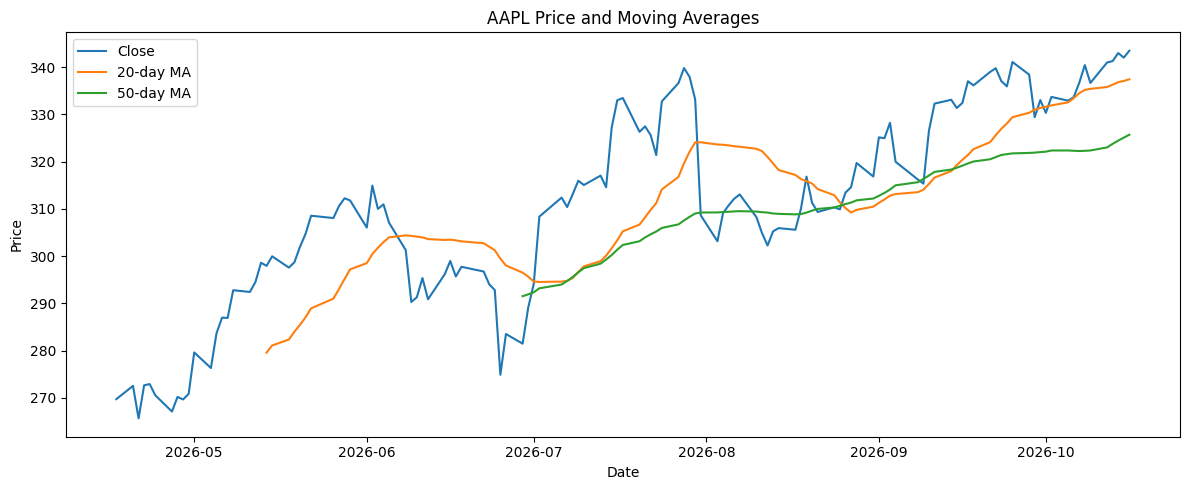

In [17]:

if not history.empty:
    chart = history.copy()
    chart["MA20"] = chart["Close"].rolling(20).mean()
    chart["MA50"] = chart["Close"].rolling(50).mean()

    plt.figure(figsize=(12, 5))
    plt.plot(chart.index, chart["Close"], label="Close")
    plt.plot(chart.index, chart["MA20"], label="20-day MA")
    plt.plot(chart.index, chart["MA50"], label="50-day MA")
    plt.title(f"{TICKER} Price and Moving Averages")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No market history returned.")


### Visualization — Interpretation

The chart makes the market trend easier to inspect than a text-only output. It also satisfies the project's requirement to include relevant visualizations demonstrating the agent workflows and functions.


## 10. Evidence-Grounded Investment Synthesis

The specialist outputs are combined into an integrated research report.

The synthesis separates:

- **Market evidence**
- **Company/financial evidence**
- **News evidence**
- **Interpretation**
- **Risk**
- **Limitations**
- **Memory context**

This structure is important because the system should distinguish observed evidence from interpretation.


In [18]:
def build_integrated_analysis(ticker, market, financials, news_summary, memory):
    """Build an evidence-grounded draft that tolerates unavailable data."""
    market = market if isinstance(market, dict) else {}
    financials = financials if isinstance(financials, dict) else {}

    def fmt(value, suffix=""):
        if value is None or (isinstance(value, float) and pd.isna(value)):
            return "Unavailable"
        try:
            return f"{float(value):.2f}{suffix}"
        except (TypeError, ValueError):
            return f"{value}{suffix}"

    company = financials.get("longName") or ticker
    sector = financials.get("sector") or "Unavailable"
    pe = financials.get("trailingPE")
    margin = financials.get("profitMargins")
    previous = [m for m in memory if str(m.get("ticker", "")).upper() == ticker.upper()]
    memory_context = (
        json.dumps(previous[-1], default=str)
        if previous else "No previous run for this ticker was found in persistent memory."
    )

    # Carry source metadata into the report so the optimizer can preserve traceability.
    news_payload = analysis_news = globals().get("news_clean", pd.DataFrame())
    source_lines = []
    if isinstance(news_payload, pd.DataFrame) and not news_payload.empty:
        for _, article in news_payload.head(10).iterrows():
            title = str(article.get("title", "") or "Untitled").strip()
            publisher = str(article.get("publisher", "") or article.get("source", "") or "Publisher unavailable").strip()
            published = str(article.get("published", "") or "Date unavailable").strip()
            link = str(article.get("link", "") or "").strip()
            link_text = link if link and link.lower() not in {"nan", "none"} else "URL unavailable"
            source_lines.append(f"- {title} | Publisher: {publisher} | Published: {published} | URL: {link_text}")
    source_section = "\\n".join(source_lines) if source_lines else "No article-level source metadata was available in this run."

    text = f"""
Investment Research Summary — {company} ({ticker})

MARKET EVIDENCE
- Latest available price: {fmt(market.get("latest_price"))}
- Return over selected period: {fmt(market.get("period_return_pct"), "%")}
- Trend signal based on the 20-day moving average: {market.get("trend_signal", "Unavailable")}
- Annualized historical volatility: {fmt(market.get("annualized_volatility_pct"), "%")}

COMPANY EVIDENCE
- Sector: {sector}
- Trailing P/E: {fmt(pe)}
- Profit margin: {fmt(margin)}

NEWS EVIDENCE
{news_summary or "No usable news summary was available."}

NEWS SOURCE REGISTER
{source_section}

INTERPRETATION
Consider market evidence together with company fundamentals and recent news. A positive trend
does not prove that a stock is undervalued, and a negative trend does not prove that the business
is deteriorating. News classification is an analytical aid, not a verified statement of causality.

RISK
Potential risks include market volatility, changing company fundamentals, regulatory or legal
developments, incomplete reporting, and delayed or inaccurate source data.

MEMORY / PRIOR LEARNING
{memory_context}

LIMITATIONS
This report uses publicly available data from the selected sources. Some fields may be missing,
delayed, or inconsistent. Verify material claims against primary filings and reliable sources.
This output is a research aid, not personalized investment advice.
""".strip()
    return text


memory = load_memory()
integrated_text = build_integrated_analysis(
    TICKER, market_result, financial_result, news_summary, memory
)
analysis = {
    "ticker": TICKER,
    "market": market_result,
    "financials": financial_result,
    "news_summary": news_summary,
    "news": news_clean,
    "integrated_analysis": integrated_text,
}
print(integrated_text)


Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.46
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.39
- Profit margin: 0.28

NEWS EVIDENCE
Apple is actively expanding its smart home ecosystem with new Home Collection accessories, an updated HomePod mini, and Apple TV 4K, all integrating Siri AI, and has partnered with Meta to run AI models on Mac computers. The company also previews future innovations like a robotic HomeView. However, Apple faces material risks, including a jury's landmark $5.7 billion patent verdict it seeks to overturn and an OpenAI allegation regarding an employee taking files about an unreleased device. The introduction of a $1,999 iPhone Duo also tests its market's status-symbol power.

NEWS SOURCE REGISTER
- Introducing Apple Home Collection, a new lineup of smart home 

### Integrated Analysis — Interpretation

The resulting report combines the independent evidence streams into one research narrative. The risk and limitation sections prevent the system from presenting financial predictions as certain conclusions.


## 11. Agent Function — Self-Reflection

The evaluator checks whether the generated analysis contains the expected evidence and responsible caveats.

The evaluation considers:

- market evidence
- financial evidence
- news evidence
- risk discussion
- uncertainty/limitations

This demonstrates the required **self-reflection** capability.


In [19]:
evaluator = EvaluatorAgent("Evaluator")

# First pass: deterministic completeness checks provide a transparent baseline.
evaluation = evaluator.evaluate(analysis)
analysis["evaluation"] = evaluation

print("Deterministic evaluation score:", round(evaluation["score"], 2))
display(pd.DataFrame([
    {"criterion": key, "passed": value}
    for key, value in evaluation["checks"].items()
]))
print("\nDeterministic feedback:")
for item in evaluation["feedback"]:
    print("-", item)

# Second pass: Gemini supplies targeted critique for the evaluator-optimizer workflow.
llm_eval_prompt = f"""
You are a careful equity-research evaluator. Audit the draft against the supplied evidence.
Do not invent facts. Identify specific omissions, unsupported claims, missing risk discussion,
uncertainty, and whether the news section contains usable article evidence.
Return ONLY valid JSON:
{{"score":7,"missing_elements":["specific missing item"],"actionable_critique":"precise instructions for revising the draft"}}
Score must be an integer from 1 to 10. Score factual grounding, usefulness, specificity, balanced
reasoning, source traceability, and risk coverage—not merely whether section headings exist.
Treat a missing source URL as missing attribution; do not assume citations exist unless shown in the draft.
The deterministic checklist score is a separate completeness measure and is not proof of report quality.
Ticker: {TICKER}
News-chain status: {news_chain_status}
Retrieved news count: {len(news_raw)}
Draft:
{analysis["integrated_analysis"]}
Deterministic checks:
{json.dumps(evaluation.get("checks", {}), default=str)}
Deterministic feedback:
{json.dumps(evaluation.get("feedback", []), default=str)}
"""
llm_eval_raw, llm_eval_error = call_gemini(llm_eval_prompt, "LLM self-reflection")
llm_eval_status = "LLM_EVALUATION_PASS" if llm_eval_raw else "DETERMINISTIC_EVALUATION_FALLBACK"
llm_evaluation_report = None

if llm_eval_raw:
    try:
        llm_evaluation_report = parse_json_response(llm_eval_raw)
        llm_evaluation_report["score"] = max(1, min(10, int(llm_evaluation_report.get("score", 5))))
        llm_evaluation_report["missing_elements"] = _as_list(llm_evaluation_report.get("missing_elements"))
        llm_evaluation_report["actionable_critique"] = str(
            llm_evaluation_report.get("actionable_critique", "")
        ).strip()
        llm_evaluation_text = (
            f"SCORE: {llm_evaluation_report['score']}/10\n"
            f"MISSING: {'; '.join(llm_evaluation_report['missing_elements']) or 'None specified'}\n"
            f"FEEDBACK: {llm_evaluation_report['actionable_critique'] or 'No specific critique returned.'}"
        )
    except Exception as exc:
        llm_eval_status = "DETERMINISTIC_EVALUATION_FALLBACK"
        llm_eval_error = f"Invalid evaluator JSON: {type(exc).__name__}: {str(exc)[:160]}"
        llm_evaluation_report = None

if llm_evaluation_report is None:
    llm_evaluation_text = (
        f"SCORE: {int(round(evaluation['score'] / 10))}/10\n"
        f"MISSING: {'; '.join(evaluation.get('feedback', [])) or 'No deterministic gaps detected'}\n"
        f"FEEDBACK: {'; '.join(evaluation.get('feedback', [])) or 'Review the report for source coverage and uncertainty.'}"
    )

print("\nLLM self-reflection status:", llm_eval_status)
print(llm_evaluation_text)
if llm_eval_error:
    print("Evaluator diagnostic:", llm_eval_error)


[Evaluator] Evaluating analysis quality
Deterministic evaluation score: 100.0


,criterion,passed
0,has_market_data,True
1,has_financial_data_or_explicit_absence,True
2,has_news_evidence_or_explicit_absence,True
3,has_article_source_attribution,True
4,has_specific_risk_discussion,True
5,has_interpretation_section,True
6,has_uncertainty_and_limitations,True
7,has_responsible_use_disclaimer,True



Deterministic feedback:


[10/19/26 13:16:15] INFO     AFC is enabled with max remote calls: 10.                               ]8;id=8114473;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py\models.py]8;;\:]8;id=8114474;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py#6224\6224]8;;\

[10/19/26 13:16:34] INFO     HTTP Request: POST                                                     ]8;id=8114481;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=8114482;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  


LLM self-reflection status: LLM_EVALUATION_PASS
SCORE: 2/10
MISSING: Specific synthesis of market, company, and news evidence in the Interpretation section.; Discussion of specific risks (patent verdict, ex-OpenAI employee allegation) and their potential implications in the Risk section.; Inline source attribution (e.g., dates, publications) for specific claims within the News Evidence summary paragraph.; Clear separation of interpretation from factual evidence in the News Evidence section.
FEEDBACK: The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are required:

1.  **Interpretation Section:** The current 'INTERPRETATION' section is a generic disclaimer. It must be revised to actively synthesize the provided market trends (Bullish 20-day MA, 27.33% return), company fundamentals (P/E 39.39, Profit Margin 0.28), and recent news (smart home expansion, iPhone Duo launch, $5.7B patent verdict, ex-OpenAI employee allegations). 

### Self-Reflection — Interpretation

The evaluator converts qualitative requirements into explicit checks and produces a score plus feedback. This makes self-reflection observable and measurable instead of simply claiming that the agent reviewed its own work.


## 12. Workflow Pattern 3 — Evaluator–Optimizer

The evaluator's feedback is passed to an Optimizer Agent.

The workflow is:

```text
Initial Analysis
      ↓
Evaluator
      ↓
Feedback
      ↓
Optimizer
      ↓
Improved Analysis
      ↓
Evaluation Again
```

This demonstrates iterative improvement.


In [20]:
# Evaluator–Optimizer: Gemini receives the draft and specific evaluator critique, then rewrites it.
before_score = evaluation["score"]
original_draft = analysis["integrated_analysis"]
optimizer = OptimizerAgent("Optimizer")

if llm_eval_status == "LLM_EVALUATION_PASS" and llm_evaluation_report:
    analysis = optimizer.optimize(
        analysis,
        evaluation,
        critique=llm_evaluation_report,
    )
    optimizer_status = analysis.get("optimizer_status", "UNKNOWN")
    optimizer_error = analysis.get("optimizer_diagnostic")
else:
    # No valid LLM critique means no LLM optimization claim; preserve the original draft.
    analysis["optimized_analysis"] = original_draft
    optimizer_status = "OPTIMIZATION_NOT_RUN_NO_VALID_LLM_CRITIQUE"
    optimizer_error = llm_eval_error

# Re-score the revised/original draft with the same deterministic evaluator.
after_evaluation = evaluator.evaluate({
    **analysis,
    "integrated_analysis": analysis["optimized_analysis"],
})
analysis["evaluation_after_optimization"] = after_evaluation

print("LLM optimizer status:", optimizer_status)
if optimizer_error:
    print("Optimizer diagnostic:", optimizer_error)
print("Score before optimization:", round(before_score, 2))
print("Score after optimization:", round(after_evaluation["score"], 2))
print("\nOPTIMIZED ANALYSIS\n")
print(analysis["optimized_analysis"])


[Optimizer] Revising the draft using evaluator feedback


                    INFO     AFC is enabled with max remote calls: 10.                               ]8;id=8114487;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py\models.py]8;;\:]8;id=8114488;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py#6224\6224]8;;\

[10/19/26 13:16:57] INFO     HTTP Request: POST                                                     ]8;id=8114493;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=8114494;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  

[Evaluator] Evaluating analysis quality
LLM optimizer status: LLM_OPTIMIZATION_PASS
Score before optimization: 100.0
Score after optimization: 100.0

OPTIMIZED ANALYSIS

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.46
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.39
- Profit margin: 0.28

NEWS EVIDENCE
Apple is actively expanding its smart home ecosystem with new Home Collection accessories (Apple, Tue, 13 Oct 2026), an updated HomePod mini with Siri AI support (Apple, Tue, 13 Oct 2026), and Apple TV 4K, also supercharged by Siri AI (Apple, Tue, 13 Oct 2026). The company has partnered with Meta to run AI models on Mac computers (CNBC, Thu, 15 Oct 2026) and previews future innovations like a robotic HomeView (Bloomberg.com, Sun, 18 Oct 2026; Reuters, Tue, 13 Oct 2026). Apple also introduc

### Evaluator–Optimizer — Interpretation

A first-pass evaluator identifies completeness gaps, and a Gemini evaluator supplies a targeted critique when available. The optimizer passes the draft and critique to Gemini and asks it to revise the full report in context—not append generic boilerplate. The same deterministic evaluator scores the revised report. If the LLM call fails, the original draft is retained and the fallback status is reported.

## 13. Agent Function — Learning Across Runs

After optimization, the system stores a memory record containing information about the run.

The goal is not to retrain the Gemini model. Instead, the agent system retains useful observations externally and can use them as context during future runs.


In [21]:
# Preview the learning record. It is persisted only after final evaluation in Section 22.
memory_critique = (
    llm_evaluation_report.get("actionable_critique", "")
    if llm_evaluation_report else "; ".join(evaluation.get("feedback", []))
)
memory_note_preview = {
    "ticker": TICKER,
    "trend_signal": market_result.get("trend_signal"),
    "evaluation_score_before_optimization": evaluation.get("score"),
    "evaluation_score_after_optimization": after_evaluation.get("score"),
    "evaluator_critique_lesson": memory_critique or "No specific critique returned; verify source coverage next run.",
    "will_be_saved_in": str(MEMORY_FILE),
}
display(pd.DataFrame([memory_note_preview]))
print("The planner reads saved critiques on the next run. This run's final record is saved in Section 22.")


,ticker,trend_signal,evaluation_score_before_optimization,evaluation_score_after_optimization,evaluator_critique_lesson,will_be_saved_in
0,AAPL,Bullish,100.0,100.0,The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are ...,investment_agent_memory.json


The planner reads saved critiques on the next run. This run's final record is saved in Section 22.


### Persistent Memory — Interpretation

The final memory record stores the actual evaluator critique, score, ticker, and trend. On a subsequent run, the planner reads recent memory for that ticker and can prioritize the previously missed issue. No synthetic example records are inserted into the FAISS memory store.

## 14. End-to-End Autonomous Workflow

The following function combines the individual components into one repeatable workflow.

It performs:

1. Planning
2. Market-data retrieval
3. Financial-data retrieval
4. News ingestion and preprocessing
5. Routing
6. Integrated analysis
7. Evaluation
8. Optimization
9. Final evaluation
10. Memory update


In [22]:
## End-to-end workflow result assembled from the executed components

def run_investment_research_result(
    ticker, plan, news_data, market_data, fundamentals, draft, initial_eval,
    optimized_report, final_eval, chain_status, routing_log, execution_log
):
    """
    Assemble the actual section-by-section execution into one auditable result.
    The function reuses outputs already retrieved above, avoiding duplicate API calls.
    """
    if str(ticker).upper() != str(plan.get("ticker", ticker)).upper():
        raise ValueError("Plan ticker and requested ticker do not match.")
    return {
        "ticker": ticker,
        "planning_method": plan.get("planning_method"),
        "planned_tasks_in_execution_order": [item.get("task") for item in plan.get("tasks", [])],
        "execution_log": execution_log,
        "news_provider": getattr(news_agent, "news_source", "Unavailable"),
        "news_articles_retrieved": int(len(news_raw)),
        "news_prompt_chain_status": chain_status,
        "news_articles_routed": int(len(news_data)),
        "routing_counts": (
            news_data["routed_to"].value_counts().to_dict()
            if not news_data.empty and "routed_to" in news_data.columns else {}
        ),
        "market_result_available": "latest_price" in market_data,
        "fundamentals_result_available": bool(fundamentals) and "error" not in fundamentals and any(value is not None for value in fundamentals.values()),
        "initial_evaluation_score": initial_eval.get("score"),
        "final_evaluation_score": final_eval.get("score"),
        "optimizer_status": optimizer_status,
        "optimized_report": optimized_report,
    }

workflow_result = run_investment_research_result(
    ticker=TICKER,
    plan=research_plan,
    news_data=news_clean,
    market_data=market_result,
    fundamentals=financial_result,
    draft=integrated_text,
    initial_eval=evaluation,
    optimized_report=analysis["optimized_analysis"],
    final_eval=after_evaluation,
    chain_status=news_chain_status,
    routing_log=news_clean.get("routed_to", pd.Series(dtype="object")),
    execution_log=execution_log,
)

print("END-TO-END WORKFLOW AUDIT")
display(pd.DataFrame([
    {"component": key, "result": json.dumps(value, default=str) if isinstance(value, (dict, list)) else value}
    for key, value in workflow_result.items() if key != "optimized_report"
]))
print("\nFinal optimized report:\n")
print(workflow_result["optimized_report"])


END-TO-END WORKFLOW AUDIT


,component,result
0,ticker,AAPL
1,planning_method,Gemini LLM
2,planned_tasks_in_execution_order,"[""news"", ""fundamentals"", ""market""]"
3,execution_log,"[{""task"": ""news"", ""status"": ""LLM_PROMPT_CHAIN_PASS"", ""focus"": ""Recent material events, product launches (e.g., smart..."
4,news_provider,Google News RSS
5,news_articles_retrieved,20
6,news_prompt_chain_status,LLM_PROMPT_CHAIN_PASS
7,news_articles_routed,20
8,routing_counts,"{""News Specialist"": 20}"
9,market_result_available,True



Final optimized report:

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.46
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.39
- Profit margin: 0.28

NEWS EVIDENCE
Apple is actively expanding its smart home ecosystem with new Home Collection accessories (Apple, Tue, 13 Oct 2026), an updated HomePod mini with Siri AI support (Apple, Tue, 13 Oct 2026), and Apple TV 4K, also supercharged by Siri AI (Apple, Tue, 13 Oct 2026). The company has partnered with Meta to run AI models on Mac computers (CNBC, Thu, 15 Oct 2026) and previews future innovations like a robotic HomeView (Bloomberg.com, Sun, 18 Oct 2026; Reuters, Tue, 13 Oct 2026). Apple also introduced a $1,999 iPhone Duo (CNBC, Fri, 16 Oct 2026). However, Apple faces material legal challenges, including a jury's landmark $5.7 billion patent

### End-to-End Workflow — Interpretation

This is the complete autonomous execution path. The earlier sections explained and tested the individual components; this function demonstrates how they operate together as one system.


## 15. Rubric Coverage Check

The following summary connects the implementation to the project requirements.

| Requirement | Implementation |
|---|---|
| Planning | Research Manager |
| Dynamic tool use | Yahoo Finance retrieval |
| Self-reflection | LLM + deterministic evaluators |
| Learning across runs | JSON memory |
| Prompt Chaining | News processing pipeline (Yahoo Finance with GDELT fallback; empty-source cases are explicitly marked) |
| Routing | Specialist selection |
| Evaluator–Optimizer | Evaluation and refinement loop |
| Visualization | Market price and moving-average chart |

This section is a reviewer-friendly map showing where each required capability appears in the notebook.


## 16. Gemini LLM Integration

The project uses Gemini 2.5 Flash as the natural-language reasoning layer. The API key is loaded from a local `.env` file rather than being stored in the notebook.

The implementation also keeps a deterministic fallback so that the project can continue to operate if the external LLM is unavailable.


In [23]:
print("Gemini/LangChain dependencies were installed in Section 2.")

Gemini/LangChain dependencies were installed in Section 2.


In [24]:
load_dotenv()
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY", "").strip()
LLM_MODEL = os.getenv("GEMINI_MODEL", "gemini-2.5-flash")
print("Gemini configuration:", "API key detected" if GOOGLE_API_KEY else "No API key detected")
print("Active LLM object:", "enabled" if llm_agent.enabled else "disabled / fallback")
print("The API key is never displayed.")


Gemini configuration: API key detected
Active LLM object: enabled
The API key is never displayed.


### Gemini Configuration 

In [25]:
# LLMResearchAgent and call_gemini were initialized before Section 6 so that
# the prompt chain, planner, evaluator, and optimizer share one configured client.
print("LLM mode:", "ON" if llm_agent.enabled else "OFF / DETERMINISTIC FALLBACK")
print("Model:", LLM_MODEL)


LLM mode: ON
Model: gemini-2.5-flash


### LLM Wrapper — Interpretation

The wrapper reports whether Gemini is active and provides a safe fallback path. When Gemini is available, the same agent workflow can use LLM-generated planning and reasoning; otherwise, deterministic outputs remain available.


## 17. LLM-Based Planning

The Research Manager can use Gemini to turn the research context into a structured plan. This strengthens the planning requirement by making the plan generated through an actual LLM rather than only hard-coded Python steps.


In [26]:
# Display the actionable plan that was generated and executed in Section 8.
llm_plan = json.dumps(research_plan, indent=2, ensure_ascii=False, default=str)
print("ACTIONABLE RESEARCH PLAN\n")
print(llm_plan)
print("\nPlanning method:", research_plan.get("planning_method"))
print("The driver executed the listed tasks in the returned order; see Section 8 execution log.")


ACTIONABLE RESEARCH PLAN

{
  "ticker": "AAPL",
  "rationale": "The user requested a balanced investment research report covering market performance, company fundamentals, and recent material news. The plan prioritizes news gathering to address prior critiques regarding the specificity, source attribution, and risk identification from news events, followed by fundamentals and market analysis to provide a comprehensive view.",
  "prior_learning_applied": "The plan prioritizes the 'news' task to directly address the repeated critique regarding the lack of specific details, source attribution, and clear separation of factual reporting from interpretation in the 'NEWS EVIDENCE' section. It also aims to ensure that specific risks identified in prior runs (e.g., patent verdict, ex-OpenAI employee allegations) are thoroughly investigated with verifiable details, which will then inform a more robust 'RISK' section.",
  "tasks": [
    {
      "task": "news",
      "focus": "Recent material even

### LLM Planning — Interpretation

This section displays the same structured plan generated and executed in Section 8; it does not make a second Gemini call. The plan includes market, fundamentals, and news tasks in an order selected using the current request and prior critique.

## 18. Evidence-Grounded Synthesis from the Optimized Report

The LLM receives structured market, financial, news, and memory evidence. It is instructed to base the research report on that evidence and to include risks and limitations.

This is evidence-grounded generation because the model is given retrieved project data rather than being asked for an unsupported stock opinion.


The synthesis displayed below is the optimized report generated in Section 12. It is reused here to avoid making an unnecessary second LLM call.

In [27]:
# The synthesis is the full revised report produced by the evaluator-optimizer loop in Section 12.
llm_synthesis = analysis.get("optimized_analysis", analysis["integrated_analysis"])
print("EVIDENCE-GROUNDED SYNTHESIS / FINAL DRAFT\n")
print(llm_synthesis)


EVIDENCE-GROUNDED SYNTHESIS / FINAL DRAFT

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.46
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.39
- Profit margin: 0.28

NEWS EVIDENCE
Apple is actively expanding its smart home ecosystem with new Home Collection accessories (Apple, Tue, 13 Oct 2026), an updated HomePod mini with Siri AI support (Apple, Tue, 13 Oct 2026), and Apple TV 4K, also supercharged by Siri AI (Apple, Tue, 13 Oct 2026). The company has partnered with Meta to run AI models on Mac computers (CNBC, Thu, 15 Oct 2026) and previews future innovations like a robotic HomeView (Bloomberg.com, Sun, 18 Oct 2026; Reuters, Tue, 13 Oct 2026). Apple also introduced a $1,999 iPhone Duo (CNBC, Fri, 16 Oct 2026). However, Apple faces material legal challenges, including a jury's landmark $5

### LLM Synthesis — Interpretation

The generated report combines the retrieved evidence into a readable investment-research narrative while retaining explicit risk and limitation statements.


## 19. LLM Self-Reflection

Gemini is also used as a qualitative evaluator. The evaluator prompt asks the model to assess whether the report contains the required evidence, risks, limitations, and appropriate uncertainty.

This complements the deterministic evaluator used earlier.


In [28]:
# Reuse the critique generated by the LLM evaluator in Section 11; no duplicate API call.
print("LLM self-reflection status:", llm_eval_status)
print(llm_evaluation_text)
if llm_eval_error:
    print("Evaluator diagnostic:", llm_eval_error)


LLM self-reflection status: LLM_EVALUATION_PASS
SCORE: 2/10
MISSING: Specific synthesis of market, company, and news evidence in the Interpretation section.; Discussion of specific risks (patent verdict, ex-OpenAI employee allegation) and their potential implications in the Risk section.; Inline source attribution (e.g., dates, publications) for specific claims within the News Evidence summary paragraph.; Clear separation of interpretation from factual evidence in the News Evidence section.
FEEDBACK: The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are required:

1.  **Interpretation Section:** The current 'INTERPRETATION' section is a generic disclaimer. It must be revised to actively synthesize the provided market trends (Bullish 20-day MA, 27.33% return), company fundamentals (P/E 39.39, Profit Margin 0.28), and recent news (smart home expansion, iPhone Duo launch, $5.7B patent verdict, ex-OpenAI employee allegations). E

### LLM Self-Reflection — Interpretation

The evaluator first runs transparent deterministic completeness checks, then asks Gemini for a specific critique when the API is available. The critique and missing elements are passed to the optimizer. If the API is unavailable or a quota error occurs, the notebook labels the fallback and does not claim an LLM evaluation pass.

## 20. LLM Evaluator–Optimizer

The optimizer receives the evaluator's feedback and is instructed to revise the research report.

This creates the complete LLM-based iterative loop:

```text
Gemini Report → Gemini Evaluation → Feedback → Gemini Optimization
```


In [29]:
# Reuse the optimizer's actual revised report from Section 12; no duplicate API call.
llm_optimized = analysis.get("optimized_analysis", analysis["integrated_analysis"])
print("Optimizer status:", optimizer_status)
print("OPTIMIZED REPORT\n")
print(llm_optimized)


Optimizer status: LLM_OPTIMIZATION_PASS
OPTIMIZED REPORT

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.46
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.39
- Profit margin: 0.28

NEWS EVIDENCE
Apple is actively expanding its smart home ecosystem with new Home Collection accessories (Apple, Tue, 13 Oct 2026), an updated HomePod mini with Siri AI support (Apple, Tue, 13 Oct 2026), and Apple TV 4K, also supercharged by Siri AI (Apple, Tue, 13 Oct 2026). The company has partnered with Meta to run AI models on Mac computers (CNBC, Thu, 15 Oct 2026) and previews future innovations like a robotic HomeView (Bloomberg.com, Sun, 18 Oct 2026; Reuters, Tue, 13 Oct 2026). Apple also introduced a $1,999 iPhone Duo (CNBC, Fri, 16 Oct 2026). However, Apple faces material legal challenges, including a jur

### LLM Optimization — Interpretation

This section displays the revised report produced by the evaluator–optimizer loop in Section 12. It reuses the existing output to avoid duplicate Gemini calls and reduce quota consumption.

## 21. Final Dual Evaluation

The optimized report is evaluated again. Using both LLM and deterministic checks gives the project two complementary forms of validation.

The LLM evaluator focuses on qualitative research quality, while the deterministic evaluator checks explicit evidence requirements.


In [30]:
final_analysis_for_eval = {
    "ticker": TICKER,
    "market": market_result,
    "financials": financial_result,
    "news_summary": news_summary,
    "news": news_clean,
    "integrated_analysis": llm_optimized,
}
deterministic_final = evaluator.evaluate(final_analysis_for_eval)
analysis["evaluation_after_optimization"] = deterministic_final

comparison = pd.DataFrame([
    {"Evaluator": "Deterministic completeness before optimization", "Score": round(evaluation["score"], 2),
     "Interpretation": "Checklist coverage; not factual accuracy"},
    {"Evaluator": "Deterministic completeness after optimization", "Score": round(deterministic_final["score"], 2),
     "Interpretation": "Checklist coverage; not factual accuracy"},
    {"Evaluator": "LLM qualitative review", "Score": (
        f"{llm_evaluation_report.get('score')}/10" if llm_evaluation_report else "Fallback"
    ), "Interpretation": "Qualitative review; inspect critique and missing items"},
])
display(comparison)
print("LLM evaluation status:", llm_eval_status)
print("LLM optimizer status:", optimizer_status)
print("Final deterministic completeness score:", round(deterministic_final["score"], 2))
print("Important: checklist completeness and LLM qualitative scores measure different things; neither proves factual accuracy.")

# Second qualitative pass: check whether the optimizer actually addressed the first critique.
llm_post_eval_report = None
llm_post_eval_status = "NOT_RUN"
llm_post_eval_error = None
if llm_agent.enabled:
    post_eval_prompt = f"""
You are independently reviewing a revised equity research report.
Compare it with the earlier evaluator findings and assess whether the revision addressed them.
Do not reward headings alone. Check whether the report contains real article source attribution,
connects market and company evidence in the interpretation, discusses specific evidence-supported
risks, preserves uncertainty, and avoids invented facts.
Return ONLY valid JSON:
{{"score":7,"addressed":["item"],"remaining_gaps":["item"],"brief_reason":"reason"}}
Score must be an integer from 1 to 10.
Earlier critique:
{json.dumps(llm_evaluation_report or {}, ensure_ascii=False, default=str)}
Revised report:
{llm_optimized}
"""
    post_eval_raw, llm_post_eval_error = call_gemini(post_eval_prompt, "Post-optimization evaluation")
    if post_eval_raw:
        try:
            llm_post_eval_report = parse_json_response(post_eval_raw)
            llm_post_eval_report["score"] = max(1, min(10, int(llm_post_eval_report.get("score", 5))))
            llm_post_eval_report["addressed"] = _as_list(llm_post_eval_report.get("addressed"))
            llm_post_eval_report["remaining_gaps"] = _as_list(llm_post_eval_report.get("remaining_gaps"))
            llm_post_eval_status = "LLM_POST_EVALUATION_PASS"
        except Exception as exc:
            llm_post_eval_error = f"Invalid post-evaluation JSON: {type(exc).__name__}: {str(exc)[:160]}"
            llm_post_eval_status = "POST_EVALUATION_FALLBACK"
    else:
        llm_post_eval_status = "POST_EVALUATION_FALLBACK"
else:
    llm_post_eval_error = "Gemini is disabled; no post-optimization LLM evaluation was run."

print("Post-optimization LLM evaluation status:", llm_post_eval_status)
if llm_post_eval_report:
    print("Post-optimization LLM score:", f"{llm_post_eval_report['score']}/10")
    print("Addressed critique items:", llm_post_eval_report["addressed"])
    print("Remaining gaps:", llm_post_eval_report["remaining_gaps"])
elif llm_post_eval_error:
    print("Post-optimization LLM evaluation diagnostic:", llm_post_eval_error)

if llm_evaluation_report:
    remaining = llm_evaluation_report.get("missing_elements", [])
    print("Initial LLM-identified gaps:", remaining)
    final_text = str(llm_optimized).lower()
    remaining_checks = {
        "source attribution": ("news source register" in final_text and ("http://" in final_text or "https://" in final_text)),
        "interpretation": "interpretation" in final_text,
        "risk discussion": "risk" in final_text,
    }
    print("Post-optimization targeted checks:", remaining_checks)


[Evaluator] Evaluating analysis quality


,Evaluator,Score,Interpretation
0,Deterministic completeness before optimization,100.0,Checklist coverage; not factual accuracy
1,Deterministic completeness after optimization,100.0,Checklist coverage; not factual accuracy
2,LLM qualitative review,2/10,Qualitative review; inspect critique and missing items


LLM evaluation status: LLM_EVALUATION_PASS
LLM optimizer status: LLM_OPTIMIZATION_PASS
Final deterministic completeness score: 100.0
Important: checklist completeness and LLM qualitative scores measure different things; neither proves factual accuracy.


                    INFO     AFC is enabled with max remote calls: 10.                               ]8;id=8114499;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py\models.py]8;;\:]8;id=8114500;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/google/genai/models.py#6224\6224]8;;\

[10/19/26 13:17:20] INFO     HTTP Request: POST                                                     ]8;id=8114505;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=8114506;file:///Users/moinuddinkureshi/climate-fever-env/lib/python3.10/site-packages/httpx/_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  

Post-optimization LLM evaluation status: LLM_POST_EVALUATION_PASS
Post-optimization LLM score: 8/10
Addressed critique items: ['Specific synthesis of market, company, and news evidence in the Interpretation section.', 'Discussion of specific risks (patent verdict, ex-OpenAI employee allegation) and their potential implications in the Risk section.', 'Inline source attribution (e.g., dates, publications) for specific claims within the News Evidence summary paragraph.', 'Clear separation of interpretation from factual evidence in the News Evidence section.']
Remaining gaps: []
Initial LLM-identified gaps: ['Specific synthesis of market, company, and news evidence in the Interpretation section.', 'Discussion of specific risks (patent verdict, ex-OpenAI employee allegation) and their potential implications in the Risk section.', 'Inline source attribution (e.g., dates, publications) for specific claims within the News Evidence summary paragraph.', 'Clear separation of interpretation from f

### Final Evaluation — Interpretation

The final evaluation provides evidence that the system did not stop after the first generated report. It completed an explicit evaluation-and-improvement cycle.


## 22. Improved Learning Across Runs

The final LLM-enhanced result is stored in persistent memory. This extends the original memory mechanism so later executions can retain information from the completed agentic workflow.


In [31]:
# Persist learning derived from the evaluator's actual critique, for use by the next planner run.
critique_lesson = (
    llm_evaluation_report.get("actionable_critique", "").strip()
    if llm_evaluation_report else "; ".join(evaluation.get("feedback", []))
)
if llm_evaluation_report and llm_evaluation_report.get("missing_elements"):
    critique_lesson = (
        critique_lesson + " Missing elements: " +
        "; ".join(llm_evaluation_report["missing_elements"])
    ).strip()

final_memory_record = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "ticker": TICKER,
    "trend_signal": market_result.get("trend_signal"),
    "period_return_pct": market_result.get("period_return_pct"),
    "evaluation_score": deterministic_final.get("score"),
    "llm_enabled": bool(llm_agent.enabled),
    "evaluator_critique_lesson": critique_lesson or "No specific critique returned; verify source coverage on the next run.",
    "lesson": critique_lesson or "No specific critique returned; verify source coverage on the next run.",
}
memory = load_memory()
memory.append(final_memory_record)
save_memory(memory)
print("Saved memory record based on the evaluator's feedback:")
display(pd.DataFrame([final_memory_record]))
print("\nRecent persistent memory:")
display(pd.DataFrame(load_memory()).tail(10))
print("On the next run, the planner reads this ticker-specific critique to adjust research focus/order.")


Saved memory record based on the evaluator's feedback:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,llm_enabled,evaluator_critique_lesson,lesson
0,2026-10-19T07:47:20.157575+00:00,AAPL,Bullish,27.325946,100.0,True,The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are ...,The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are ...



Recent persistent memory:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson,llm_enabled,evaluator_critique_lesson
0,2026-10-18T18:25:53.768206+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN,NaN
1,2026-10-18T18:26:23.568205+00:00,AAPL,Bullish,27.325946,80.0,Use prior trend/evaluation context when planning the next research run.,True,NaN
2,2026-10-18T19:14:05.152760+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN,NaN
3,2026-10-18T19:14:15.868887+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN,NaN
4,2026-10-18T19:14:49.478755+00:00,AAPL,Bullish,27.325946,80.0,Use prior trend/evaluation context when planning the next research run.,True,NaN
5,2026-10-19T06:54:40.171416+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN,NaN
6,2026-10-19T06:55:13.239243+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True,NaN
7,2026-10-19T07:25:06.680977+00:00,AAPL,Bullish,27.325946,100.0,"1. **Interpretation Section**: Revise the 'INTERPRETATION' section to synthesize the provided market trends, company...",True,"1. **Interpretation Section**: Revise the 'INTERPRETATION' section to synthesize the provided market trends, company..."
8,2026-10-19T07:37:05.745180+00:00,AAPL,Bullish,27.325946,100.0,1. **Interpretation Section:** Revise the 'INTERPRETATION' section to synthesize the provided market trends (Bullish...,True,1. **Interpretation Section:** Revise the 'INTERPRETATION' section to synthesize the provided market trends (Bullish...
9,2026-10-19T07:47:20.157575+00:00,AAPL,Bullish,27.325946,100.0,The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are ...,True,The draft has not incorporated the specific feedback provided in the previous evaluation. Significant revisions are ...


On the next run, the planner reads this ticker-specific critique to adjust research focus/order.


### Improved Memory — Interpretation

The final memory record contains the current run's evaluator critique rather than a hard-coded generic lesson. On later runs, the planner reads recent ticker-specific critique records and uses them to select the task order and focus. This provides a concrete, inspectable mechanism for learning across runs.

## 23. Final Architecture

The complete system can be summarized as:

```text
                 User / Stock Symbol
                        ↓
               Research Manager
                  Gemini LLM
                        ↓
        ┌───────────────┼───────────────┐
        ↓               ↓               ↓
   Market Agent     News Agent     Earnings Agent
        └───────────────┼───────────────┘
                        ↓
              Evidence Synthesis
                        ↓
                 LLM Evaluator
                        ↓
                  Optimizer
                        ↓
             Deterministic Check
                        ↓
                Persistent Memory
                        ↓
                 Final Report
```

This architecture demonstrates how planning, tools, specialist agents, LLM reasoning, evaluation, optimization, and memory work together.


## Results Interpretation and Reproducibility

The notebook is designed to produce an inspectable research artifact rather than a single opaque recommendation.

- **Market tables and charts** describe historical observations and technical indicators for the selected period; they are not forecasts.
- **Fundamental metrics** reflect fields available from the provider and may be missing, delayed, or revised.
- **News summaries and sentiment** depend on retrieved article text and source metadata. Headlines alone are insufficient for strong conclusions.
- **Evaluation scores** summarize implemented checks. They should be accompanied by individual check results and evaluator feedback.
- **Memory records** provide continuity across runs, but stored summaries can become stale and should not override current evidence.

For reproducibility, record the ticker, analysis period, run timestamp, provider availability, and whether Gemini was enabled. Do not report numerical performance claims unless supported by an explicit evaluation procedure and saved outputs.
- **Source attribution:** the final report includes a source register built from available article metadata. Missing URLs or dates are explicitly marked unavailable rather than fabricated.
- **Score interpretation:** deterministic scores are completeness-check percentages; LLM scores are qualitative judgments on a 1–10 scale. They are different measures and neither guarantees factual accuracy.


## 24. Limitations and Responsible Use

The system is a financial-research demonstration, not personalized investment advice.

Important limitations include:

- Financial and news data can be incomplete or delayed.
- Market trends do not guarantee future returns.
- LLM-generated explanations can contain errors.
- Evaluation scores are indicators of output quality, not proof of factual correctness.
- Persistent memory is lightweight JSON storage rather than a production-grade memory service.

These limitations are intentionally included so the system does not present generated financial analysis as certainty.


## Team Contribution and Submission Checklist

This is a shared team project. Review and accurately describe each member's actual contribution (for example, architecture, data retrieval, specialist implementation, evaluation, UI/deployment, testing, or documentation). 

## 25. AI-Assistance Disclosure

AI-assisted tools were used during development to support code organization, debugging, explanation, and documentation. Gemini 2.5 Flash is also an intentional component of the implemented system for planning, synthesis, evaluation, and optimization.


# References

Google. (2026). *Gemini API documentation*. Google AI for Developers. https://ai.google.dev/gemini-api/docs

LangChain. (2026). *LangChain documentation*. https://python.langchain.com/docs/

Matplotlib Development Team. (2026). *Matplotlib documentation*. https://matplotlib.org/stable/

NumPy Developers. (2026). *NumPy documentation*. https://numpy.org/doc/

Pandas Development Team. (2026). *Pandas documentation*. https://pandas.pydata.org/docs/

scikit-learn developers. (2026). *Scikit-learn: Machine learning in Python*. https://scikit-learn.org/stable/

Yahoo Finance. (2026). *Yahoo Finance*. https://finance.yahoo.com/

yfinance developers. (2026). *yfinance documentation*. https://ranaroussi.github.io/yfinance/

University of San Diego. (2026). *Final Team Project: Multi-Agent Financial Analysis System*. AAI-335 course assignment materials.